# 银行开户欺诈分析：BAF Base

全量 1,000,000 条记录。完成数据检查、时间划分、三种监督模型、无监督基线、SHAP 与规则蒸馏、公平性与漂移，以及事后补充分析和四窗口滚动时间回测。

此 Notebook 展示已冻结实验的实际产物；重复运行只读取结果，不再选择模型或阈值。完整重跑：在项目根目录执行 `python run_analysis.py --retrain`。

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "outputs").exists():
    ROOT = ROOT.parent
OUT = ROOT / "outputs"
evaluation = json.loads((OUT / "evaluation.json").read_text(encoding="utf-8"))
explanation = json.loads((OUT / "explanation.json").read_text(encoding="utf-8"))
def table(name):
    display(pd.read_csv(OUT / "tables" / name))
def figure(name):
    display(Image(filename=str(OUT / "figures" / name)))
print("执行解释器：", sys.executable)
print("模型选择仅使用 month=6 验证集。监督模型验证胜者：", evaluation["manifest"]["supervised_winner"])
print("最终测试时间：", evaluation["evaluation_time_singapore"])


执行解释器： D:\bank_fraud_analysis\.venv\Scripts\python.exe
模型选择仅使用 month=6 验证集。监督模型验证胜者： lightgbm
最终测试时间： 2026-10-18T00:09:51.937286+08:00


## 1. 数据检查

这是基于匿名真实银行开户数据生成的合成基准。原始 CSV 没有原生空值，但存在官方定义的缺失哨兵。五列的 -1 和 intended_balcon_amount 的所有负数设为缺失；velocity_6h 和 credit_risk_score 的合法负数保留。数值填补、标准化和类别编码均只在训练期拟合。

,column,raw_dtype,role,native_missing_count,minus_one_count,negative_count,effective_missing_count,effective_missing_fraction,raw_unique_count,constant,raw_min,raw_max,handling
0,fraud_bool,int64,target,0,0,0,0,0.000000,2,False,0.000000e+00,1.000000,native null only
1,income,float64,feature,0,0,0,0,0.000000,9,False,1.000000e-01,0.900000,native null only
2,name_email_similarity,float64,feature,0,0,0,0,0.000000,998861,False,1.434550e-06,0.999999,native null only
3,prev_address_months_count,int64,feature,0,712920,712920,712920,0.712920,374,False,-1.000000e+00,383.000000,-1 means missing (official datasheet Q7)
4,current_address_months_count,int64,feature,0,4254,4254,4254,0.004254,423,False,-1.000000e+00,428.000000,-1 means missing (official datasheet Q7)
5,customer_age,int64,feature,0,0,0,0,0.000000,9,False,1.000000e+01,90.000000,native null only
6,days_since_request,float64,feature,0,0,0,0,0.000000,989330,False,4.036860e-09,78.456904,native null only
7,intended_balcon_amount,float64,feature,0,0,742523,742523,0.742523,994971,False,-1.553055e+01,112.956928,all negative values mean missing (official dat...
8,payment_type,object,feature,0,0,0,0,0.000000,5,False,NaN,NaN,native null only
9,zip_count_4w,int64,feature,0,0,0,0,0.000000,6306,False,1.000000e+00,6700.000000,native null only


,split,months,rows,fraud_count,legitimate_count,fraud_rate
0,all,"0,1,2,3,4,5,6,7",1000000,11029,988971,0.011029
1,train,"0,1,2,3,4,5",794989,8151,786838,0.010253
2,validation,6,108168,1450,106718,0.013405
3,test,7,96843,1428,95415,0.014746


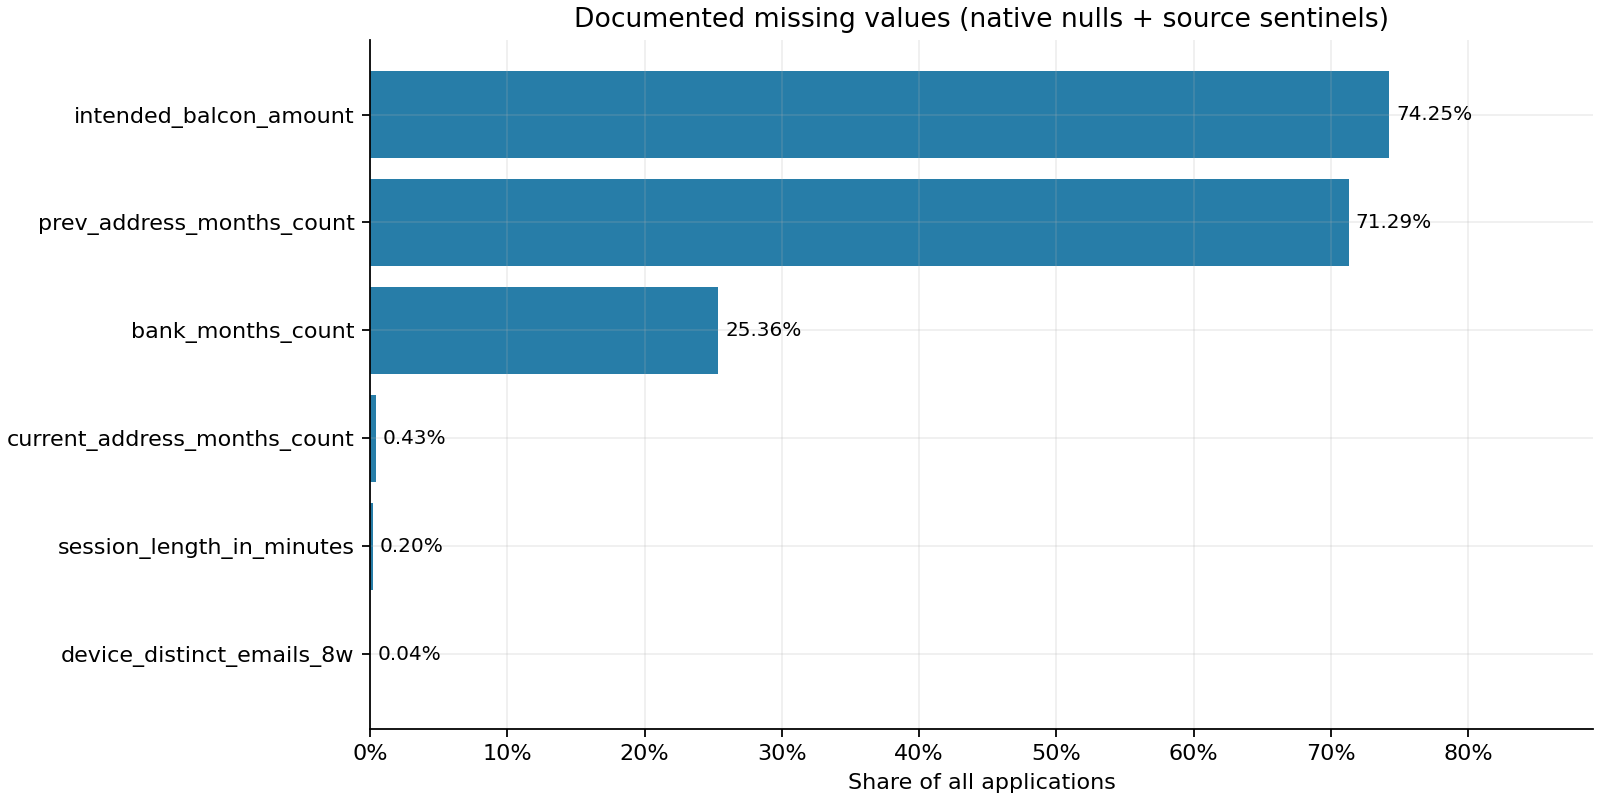

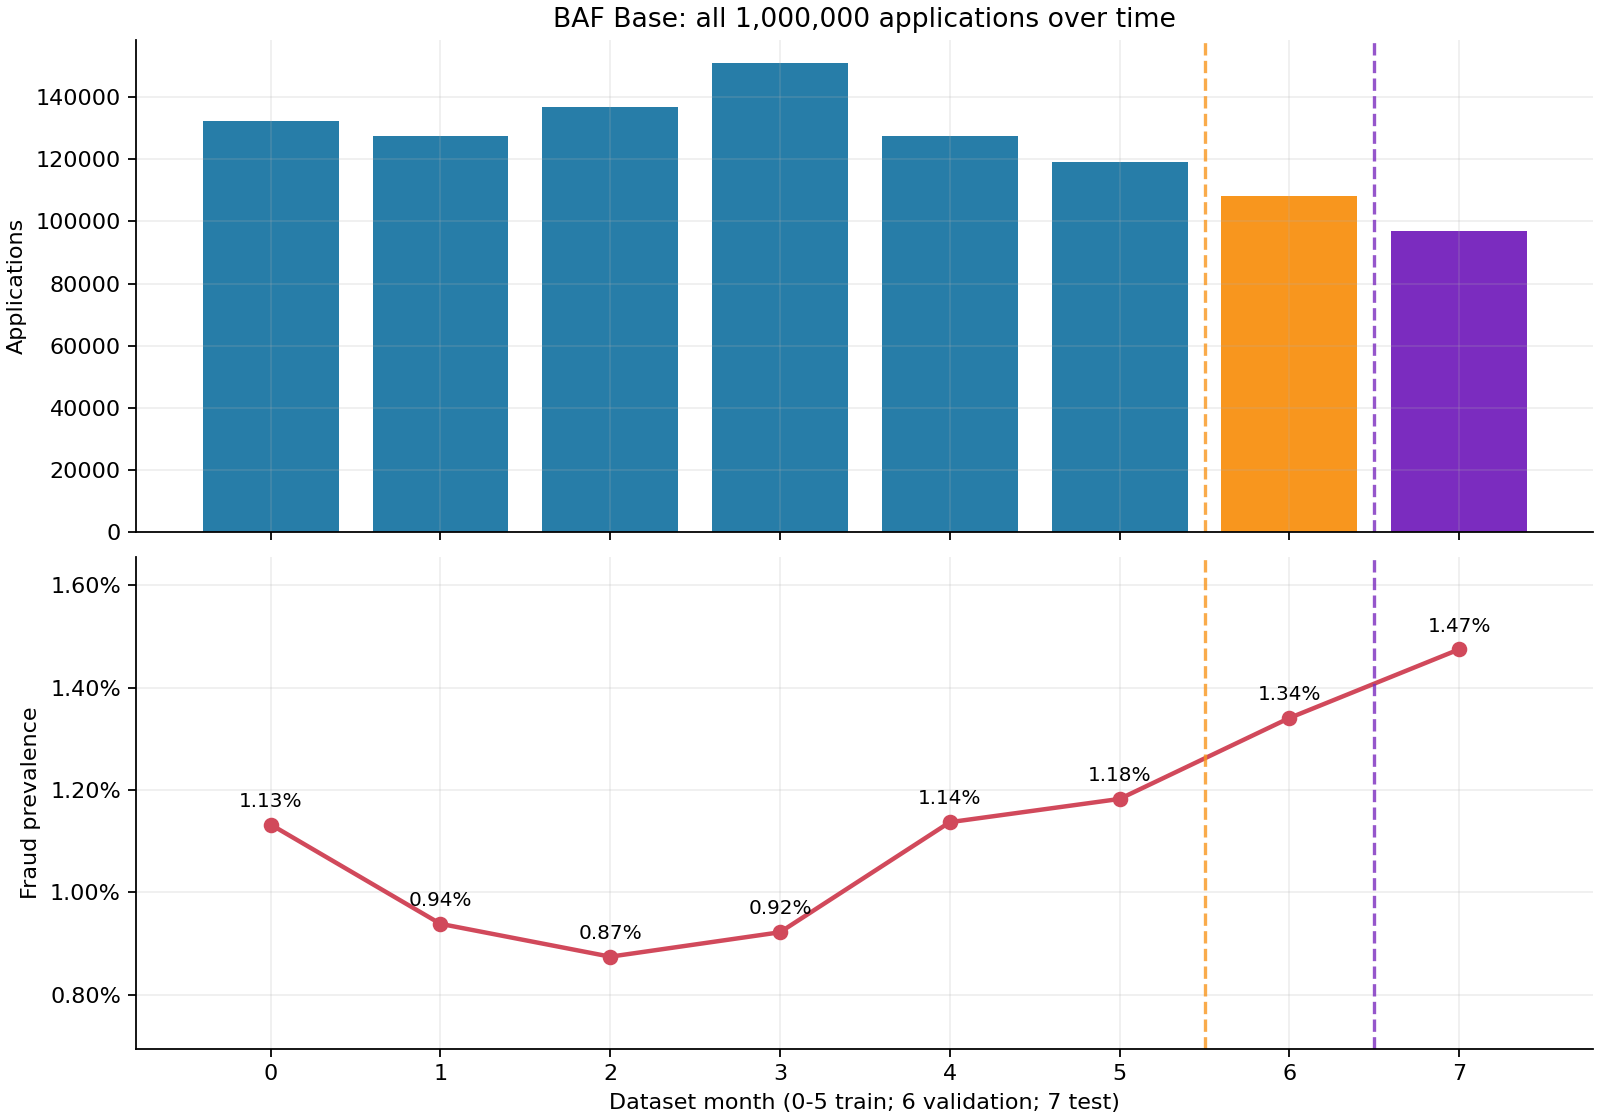

In [2]:
table("eda_schema.csv")
table("eda_split_summary.csv")
figure("eda_missing_values.png")
figure("eda_monthly_volume_fraud.png")

## 2. 按时间划分

原始 month=0–7 对应第 1–8 月。0–5 训练，6 验证，7 最终测试。month 只负责切分并从预测特征中排除；训练期常量字段也剔除。年龄保留在主模型中，公平性另作审计。

不以随机拆分替代时间拆分；不在最终测试月调参、调阈值或改规则。

In [3]:
print(json.dumps(evaluation["manifest"]["split"], indent=2))
print(evaluation["manifest"]["selection"])
table("validation_candidates.csv")

{
  "train": [
    0,
    1,
    2,
    3,
    4,
    5
  ],
  "validation": [
    6
  ],
  "test": [
    7
  ]
}
maximize validation recall under FPR<=0.05; AP breaks ties


,family,candidate,params,fit_seconds,n,fraud,tp,fp,fn,tn,recall,fpr,precision,alerts,alert_rate,threshold,pr_auc_ap,pr_auc_trapezoid,roc_auc
0,logistic_regression,LR_C0.1,"{""C"": 0.1, ""class_weight"": ""balanced"", ""max_it...",12.982643,108168,1450,734,5335,716,101383,0.506207,0.049992,0.120942,6069,0.056107,0.788095,0.155443,0.154741,0.882207
1,logistic_regression,LR_C1.0,"{""C"": 1.0, ""class_weight"": ""balanced"", ""max_it...",12.490535,108168,1450,734,5335,716,101383,0.506207,0.049992,0.120942,6069,0.056107,0.788130,0.155437,0.154736,0.882210
2,lightgbm,LGBM_leaves15,"{""num_leaves"": 15, ""reg_lambda"": 5.0, ""best_it...",23.532464,108168,1450,754,5335,696,101383,0.520000,0.049992,0.123830,6089,0.056292,0.823250,0.180138,0.179725,0.892147
3,lightgbm,LGBM_leaves31,"{""num_leaves"": 31, ""reg_lambda"": 10.0, ""best_i...",16.776912,108168,1450,767,5335,683,101383,0.528966,0.049992,0.125696,6102,0.056412,0.814578,0.176903,0.176421,0.891090
4,lightgbm,LGBM_leaves63,"{""num_leaves"": 63, ""reg_lambda"": 20.0, ""best_i...",21.122749,108168,1450,752,5335,698,101383,0.518621,0.049992,0.123542,6087,0.056274,0.794636,0.177022,0.176323,0.890842
5,mlp,MLP_lr0.001,"{""hidden_layer_sizes"": [64, 32], ""learning_rat...",19.596925,108168,1450,727,5335,723,101383,0.501379,0.049992,0.119927,6062,0.056042,0.821519,0.160769,0.160153,0.885025
6,mlp,MLP_lr0.0004,"{""hidden_layer_sizes"": [64, 32], ""learning_rat...",46.486514,108168,1450,732,5335,718,101383,0.504828,0.049992,0.120653,6067,0.056089,0.823084,0.158443,0.157813,0.885179
7,isolation_forest,IF_250_4096,"{""n_estimators"": 250, ""max_samples"": 4096, ""la...",6.269517,108168,1450,104,5335,1346,101383,0.071724,0.049992,0.019121,5439,0.050283,0.487476,0.015905,0.015847,0.560414


## 3. 三种监督模型

逻辑回归、LightGBM、MLP 使用类别权重。PR-AUC 主口径为 Average Precision（AP）；梯形积分口径另行导出。每个模型在验证月选取满足 FPR≤5% 的最低可行整分数阈值，冻结后应用于测试月，因此测试 FPR 不保证恰好 5%。

FPR=FP/(FP+TN)，总告警率=(TP+FP)/N，两者含义不同。

,model,n,fraud,tp,fp,fn,tn,recall,fpr,precision,alerts,alert_rate,threshold,pr_auc_ap,pr_auc_trapezoid,roc_auc,recall_ci,fpr_ci
0,logistic_regression,108168,1450,734,5335,716,101383,0.506207,0.049992,0.120942,6069,0.056107,0.788095,0.155443,0.154741,0.882207,"[0.48049090625262, 0.5318900861112936]","[0.04870018886551866, 0.05131534041055051]"
1,lightgbm,108168,1450,767,5335,683,101383,0.528966,0.049992,0.125696,6102,0.056412,0.814578,0.176903,0.176421,0.891090,"[0.5032304664613796, 0.5545474979035505]","[0.04870018886551866, 0.05131534041055051]"
2,mlp,108168,1450,732,5335,718,101383,0.504828,0.049992,0.120653,6067,0.056089,0.823084,0.158443,0.157813,0.885179,"[0.47911446009906566, 0.5305152006284227]","[0.04870018886551866, 0.05131534041055051]"
3,isolation_forest,108168,1450,104,5335,1346,101383,0.071724,0.049992,0.019121,5439,0.050283,0.487476,0.015905,0.015847,0.560414,"[0.05954399674249148, 0.08616753014747104]","[0.04870018886551866, 0.05131534041055051]"
4,distilled_tree,108168,1450,0,0,1450,106718,0.000000,0.000000,0.000000,0,0.000000,1.001170,0.047345,0.211635,0.784780,"[0.0, 0.002642281795849991]","[0.0, 3.599505750822492e-05]"


,model,n,fraud,tp,fp,fn,tn,recall,fpr,precision,alerts,alert_rate,threshold,pr_auc_ap,pr_auc_trapezoid,roc_auc,recall_ci,fpr_ci
0,logistic_regression,96843,1428,644,3265,784,92150,0.450980,0.034219,0.164748,3909,0.040364,0.788095,0.184793,0.184395,0.886879,"[0.42533807136126517, 0.47688574040396486]","[0.03308407484984483, 0.03539130547260922]"
1,lightgbm,96843,1428,761,4175,667,91240,0.532913,0.043756,0.154173,4936,0.050969,0.814578,0.210447,0.209799,0.892808,"[0.5069826206845619, 0.5586671057016409]","[0.04247657862167973, 0.04507260276746874]"
2,mlp,96843,1428,780,5065,648,90350,0.546218,0.053084,0.133447,5845,0.060355,0.823084,0.189480,0.189058,0.886307,"[0.5203068105440921, 0.5718821669344053]","[0.0516792231758904, 0.05452455486090426]"
3,isolation_forest,96843,1428,126,5994,1302,89421,0.088235,0.062820,0.020588,6120,0.063195,0.487476,0.018706,0.018623,0.574321,"[0.07460713365429711, 0.10407288517363403]","[0.06129826565995569, 0.0643775576416292]"
4,distilled_tree,96843,1428,0,0,1428,95415,0.000000,0.000000,0.000000,0,0.000000,1.001170,0.055040,0.236868,0.791717,"[0.0, 0.002682880005344901]","[0.0, 4.0258912830667174e-05]"


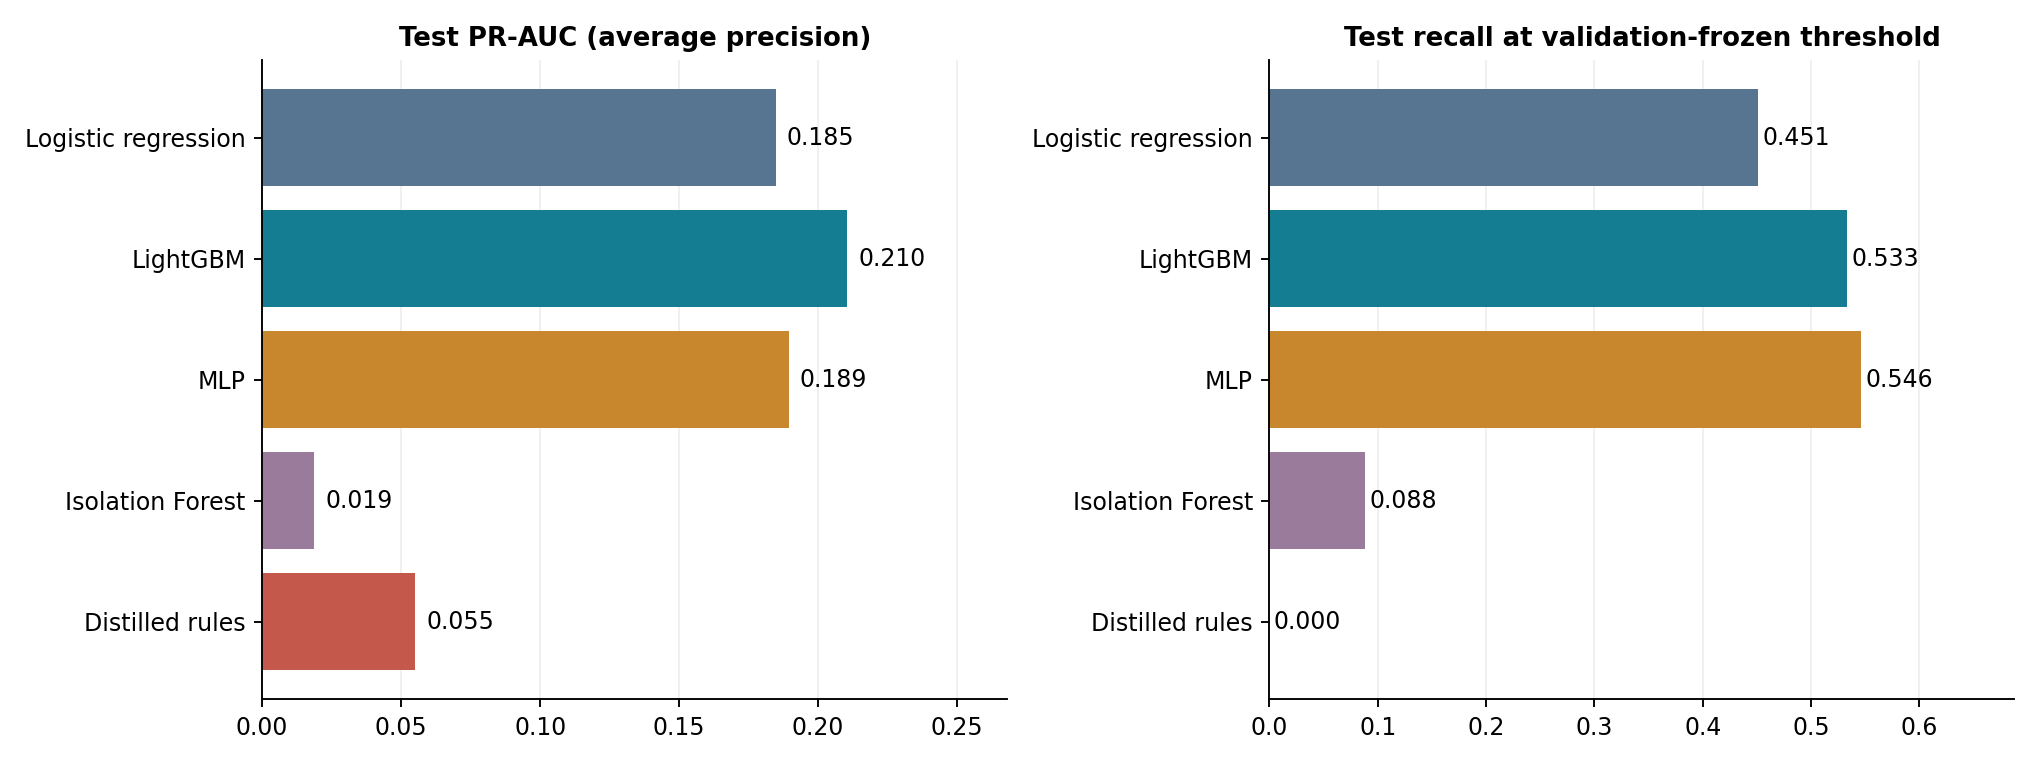

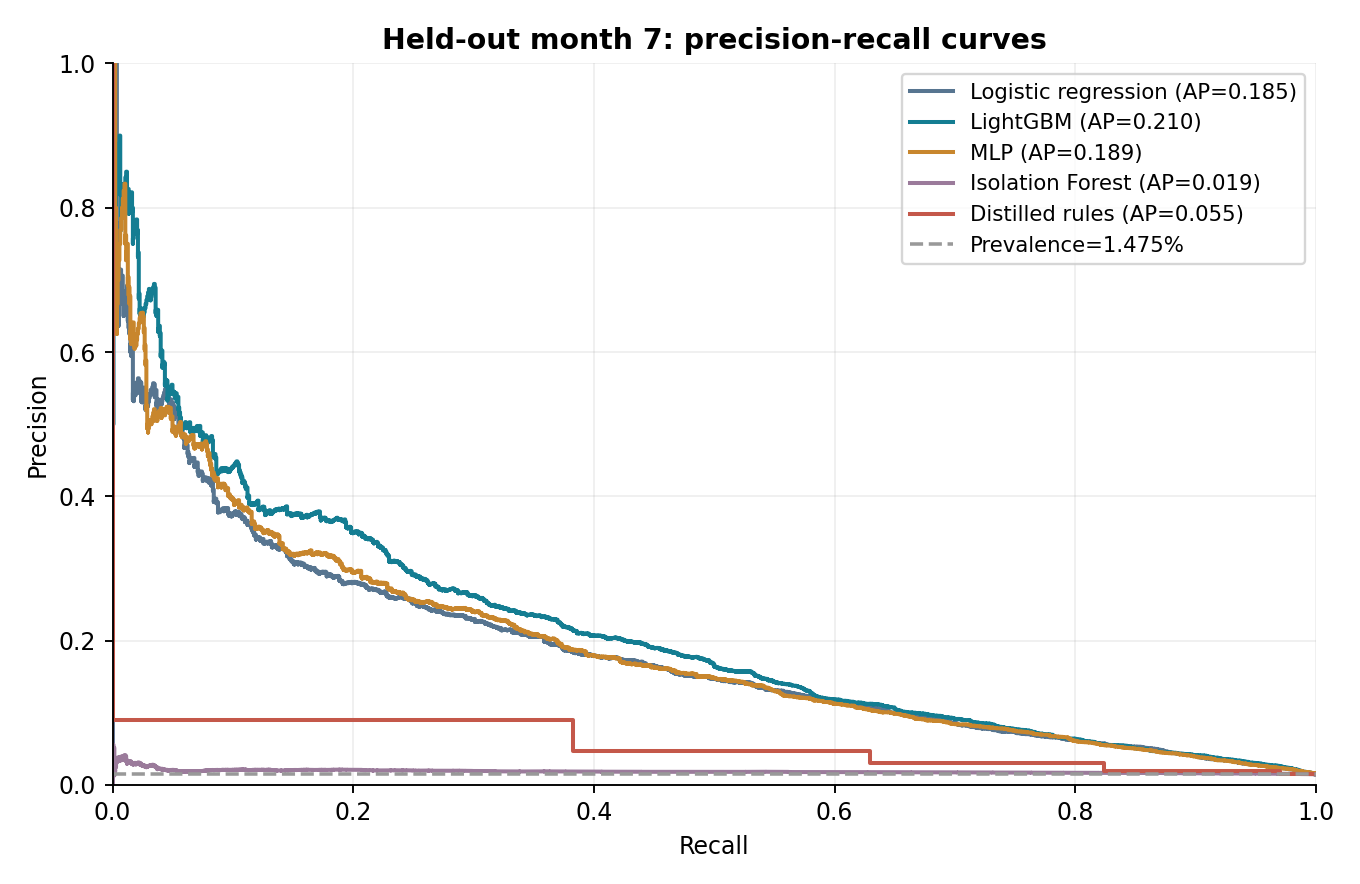

In [4]:
table("validation_metrics.csv")
table("test_metrics.csv")
figure("benchmark.png")
figure("pr_curves.png")

## 4. 无监督对照

Isolation Forest 使用预先指定的一套参数，仅在训练期特征上拟合，不使用欺诈标签。为与监督模型的业务约束一致，其报警阈值仍使用验证标签校准，所以这是“无标签拟合 + 有标签阈值校准”的基线。

In [5]:
display(pd.DataFrame(evaluation["test_results"]).query("model == 'isolation_forest'"))

,model,n,fraud,tp,fp,fn,tn,recall,fpr,precision,alerts,alert_rate,threshold,pr_auc_ap,pr_auc_trapezoid,roc_auc,recall_ci,fpr_ci
3,isolation_forest,96843,1428,126,5994,1302,89421,0.088235,0.06282,0.020588,6120,0.063195,0.487476,0.018706,0.018623,0.574321,"[0.07460713365429711, 0.10407288517363403]","[0.06129826565995569, 0.0643775576416292]"


## 5. SHAP 与规则蒸馏

对验证月随机抽取 5,000 条记录计算原生精确 TreeSHAP，并验证贡献之和等于模型原始 log-odds。SHAP 描述模型如何使用特征，不表示因果影响。

学生树拟合训练集上的 LightGBM log-odds，深度候选为 3/4，最多五个叶节点。下面五条互斥路径是风险分档，按学生预测风险排序。显示阈值已回到原字段单位，数字经过舍入；精确执行以已保存模型为准。缺失值需先按训练中位数填补。

,feature,mean_abs_shap
0,device_os,0.519541
1,phone_home_valid,0.454398
2,housing_status,0.440439
3,name_email_similarity,0.397089
4,prev_address_months_count,0.381699
5,has_other_cards,0.353462
6,current_address_months_count,0.326053
7,keep_alive_session,0.325346
8,email_is_free,0.321136
9,income,0.293989


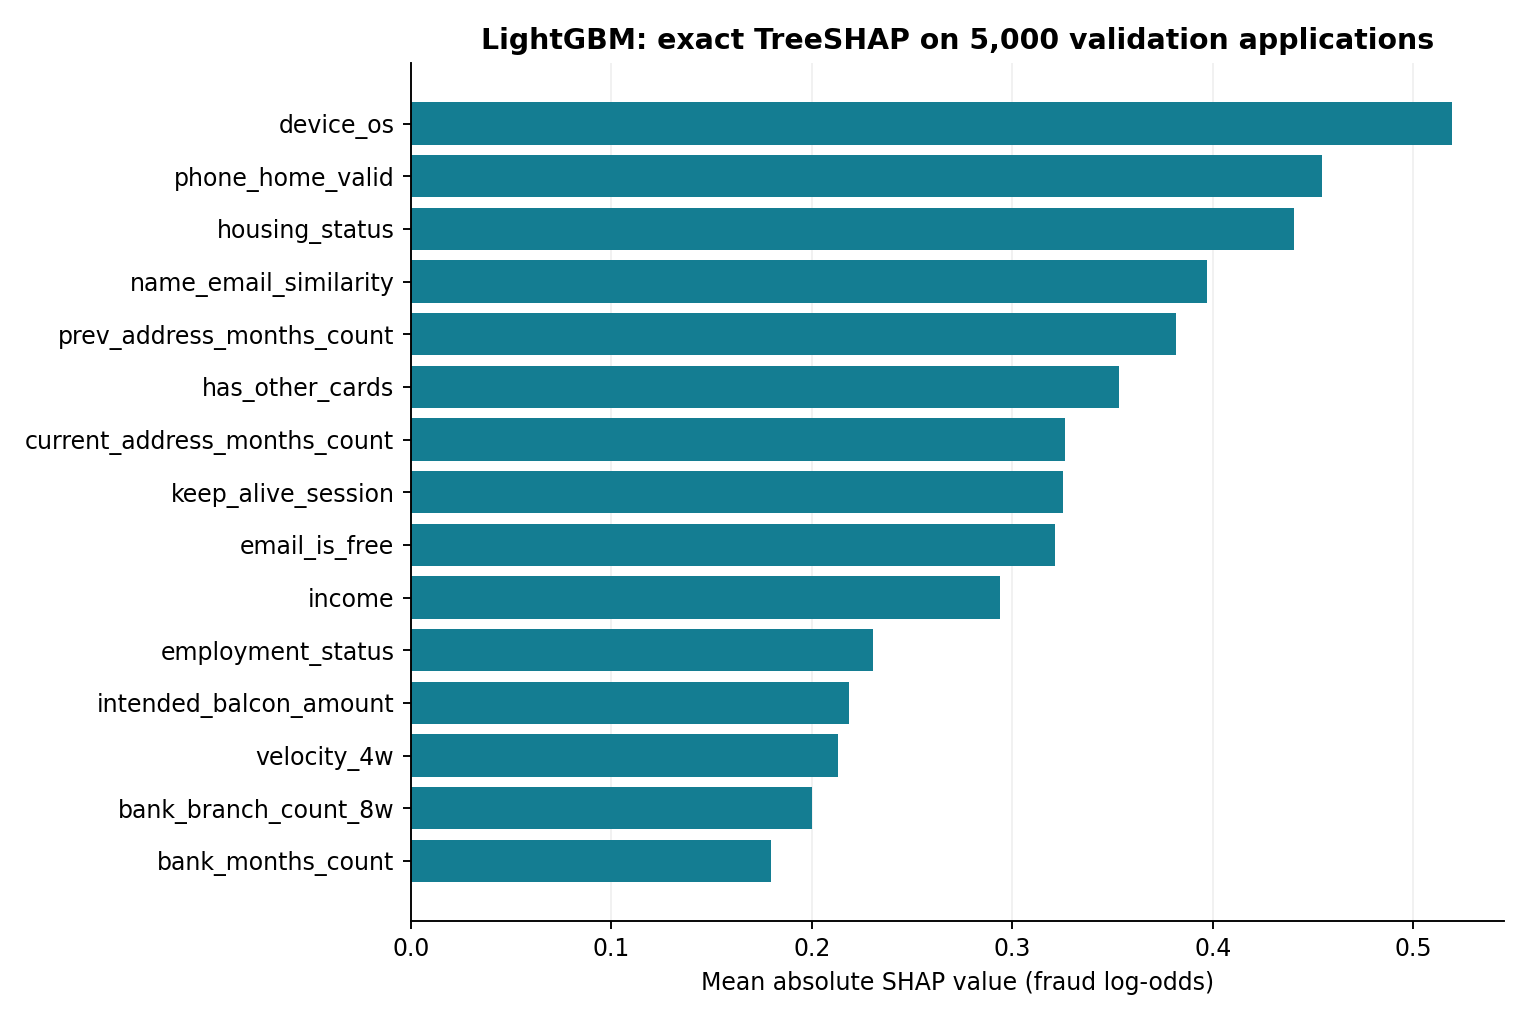

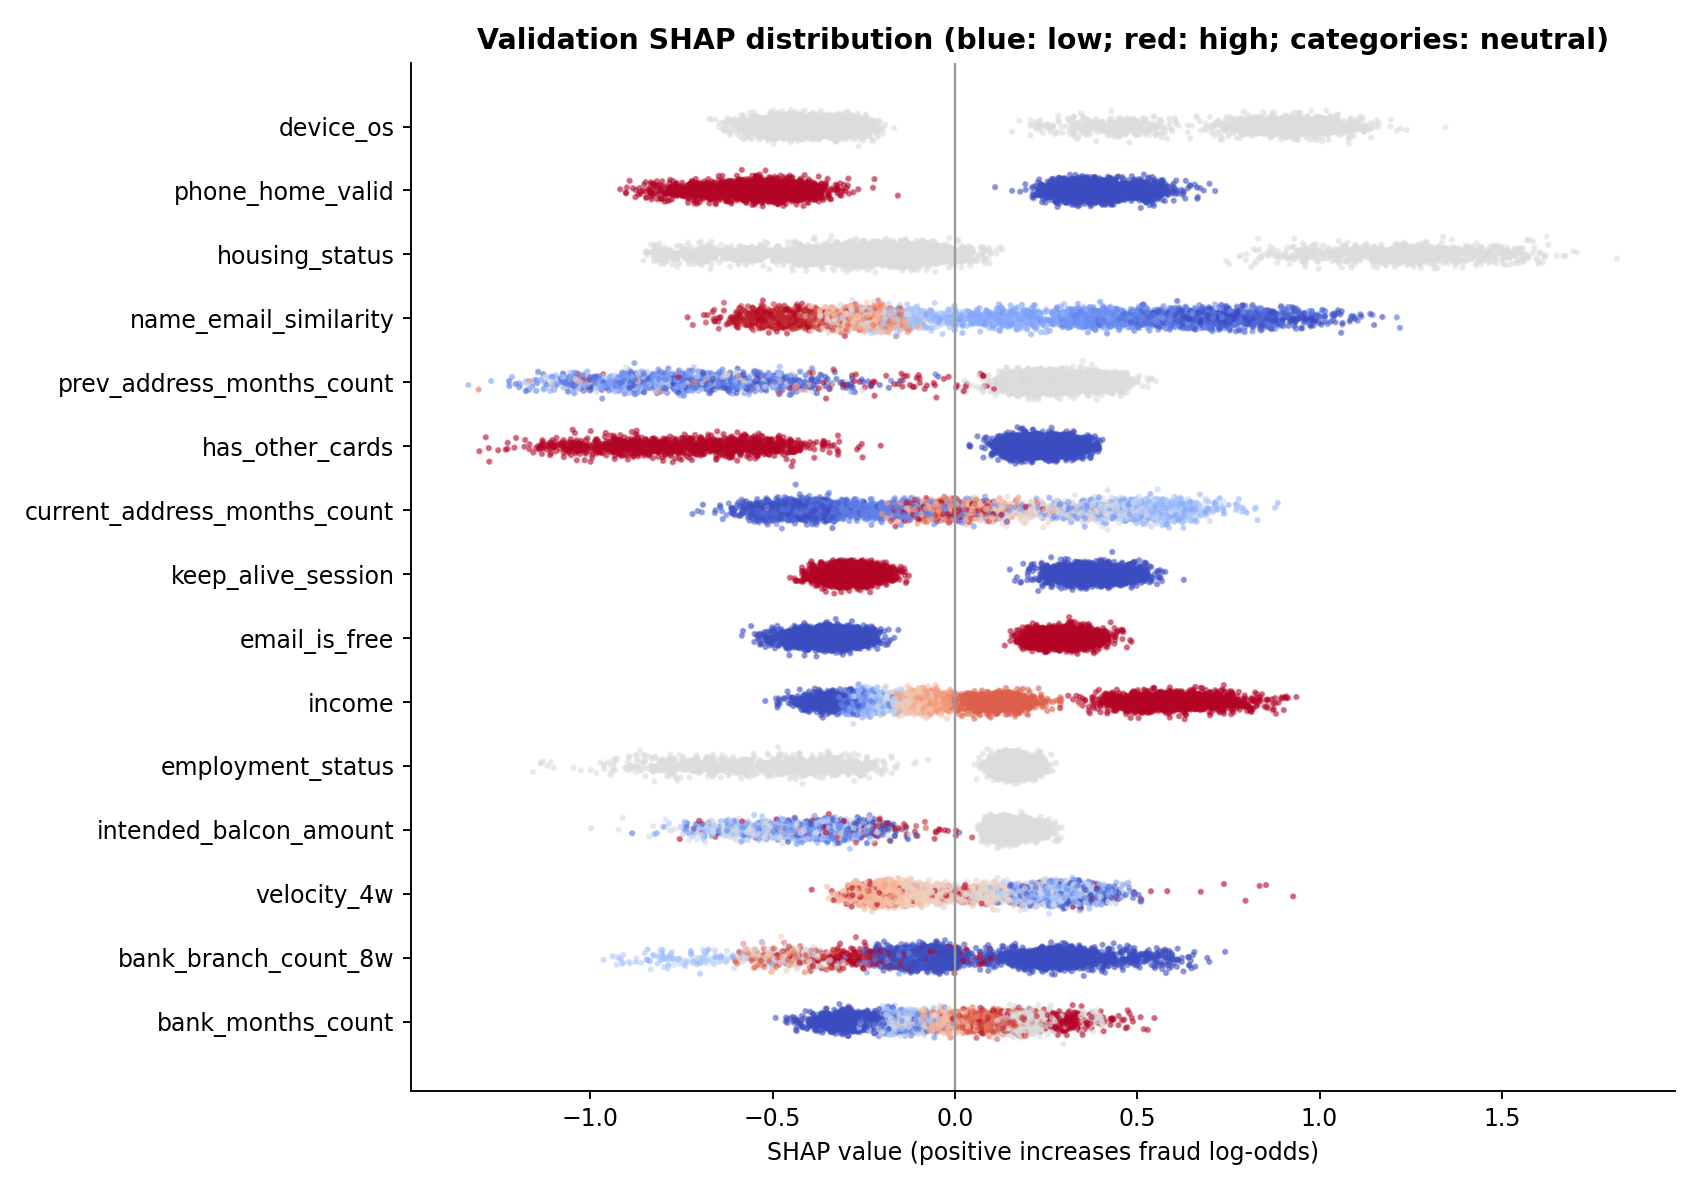

,rule_id,node_id,path,teacher_log_odds,train_rows,validation_rows,test_rows,test_fraud,test_fraud_rate,frozen_threshold_alert
0,R1,8,housing_status 等于 BA 且 device_os 等于 windows,1.001170,45597,6241,6090,546,0.089655,False
1,R2,7,housing_status 等于 BA 且 device_os 不等于 windows,-0.387884,84178,14477,13092,353,0.026963,False
2,R3,4,housing_status 不等于 BA 且 device_os 等于 windows,-1.113996,167328,19198,19052,278,0.014592,False
3,R4,6,housing_status 不等于 BA 且 device_os 不等于 windows ...,-2.202226,338138,49087,35596,209,0.005871,False
4,R5,5,housing_status 不等于 BA 且 device_os 不等于 windows ...,-3.452819,159748,19165,23013,42,0.001825,False


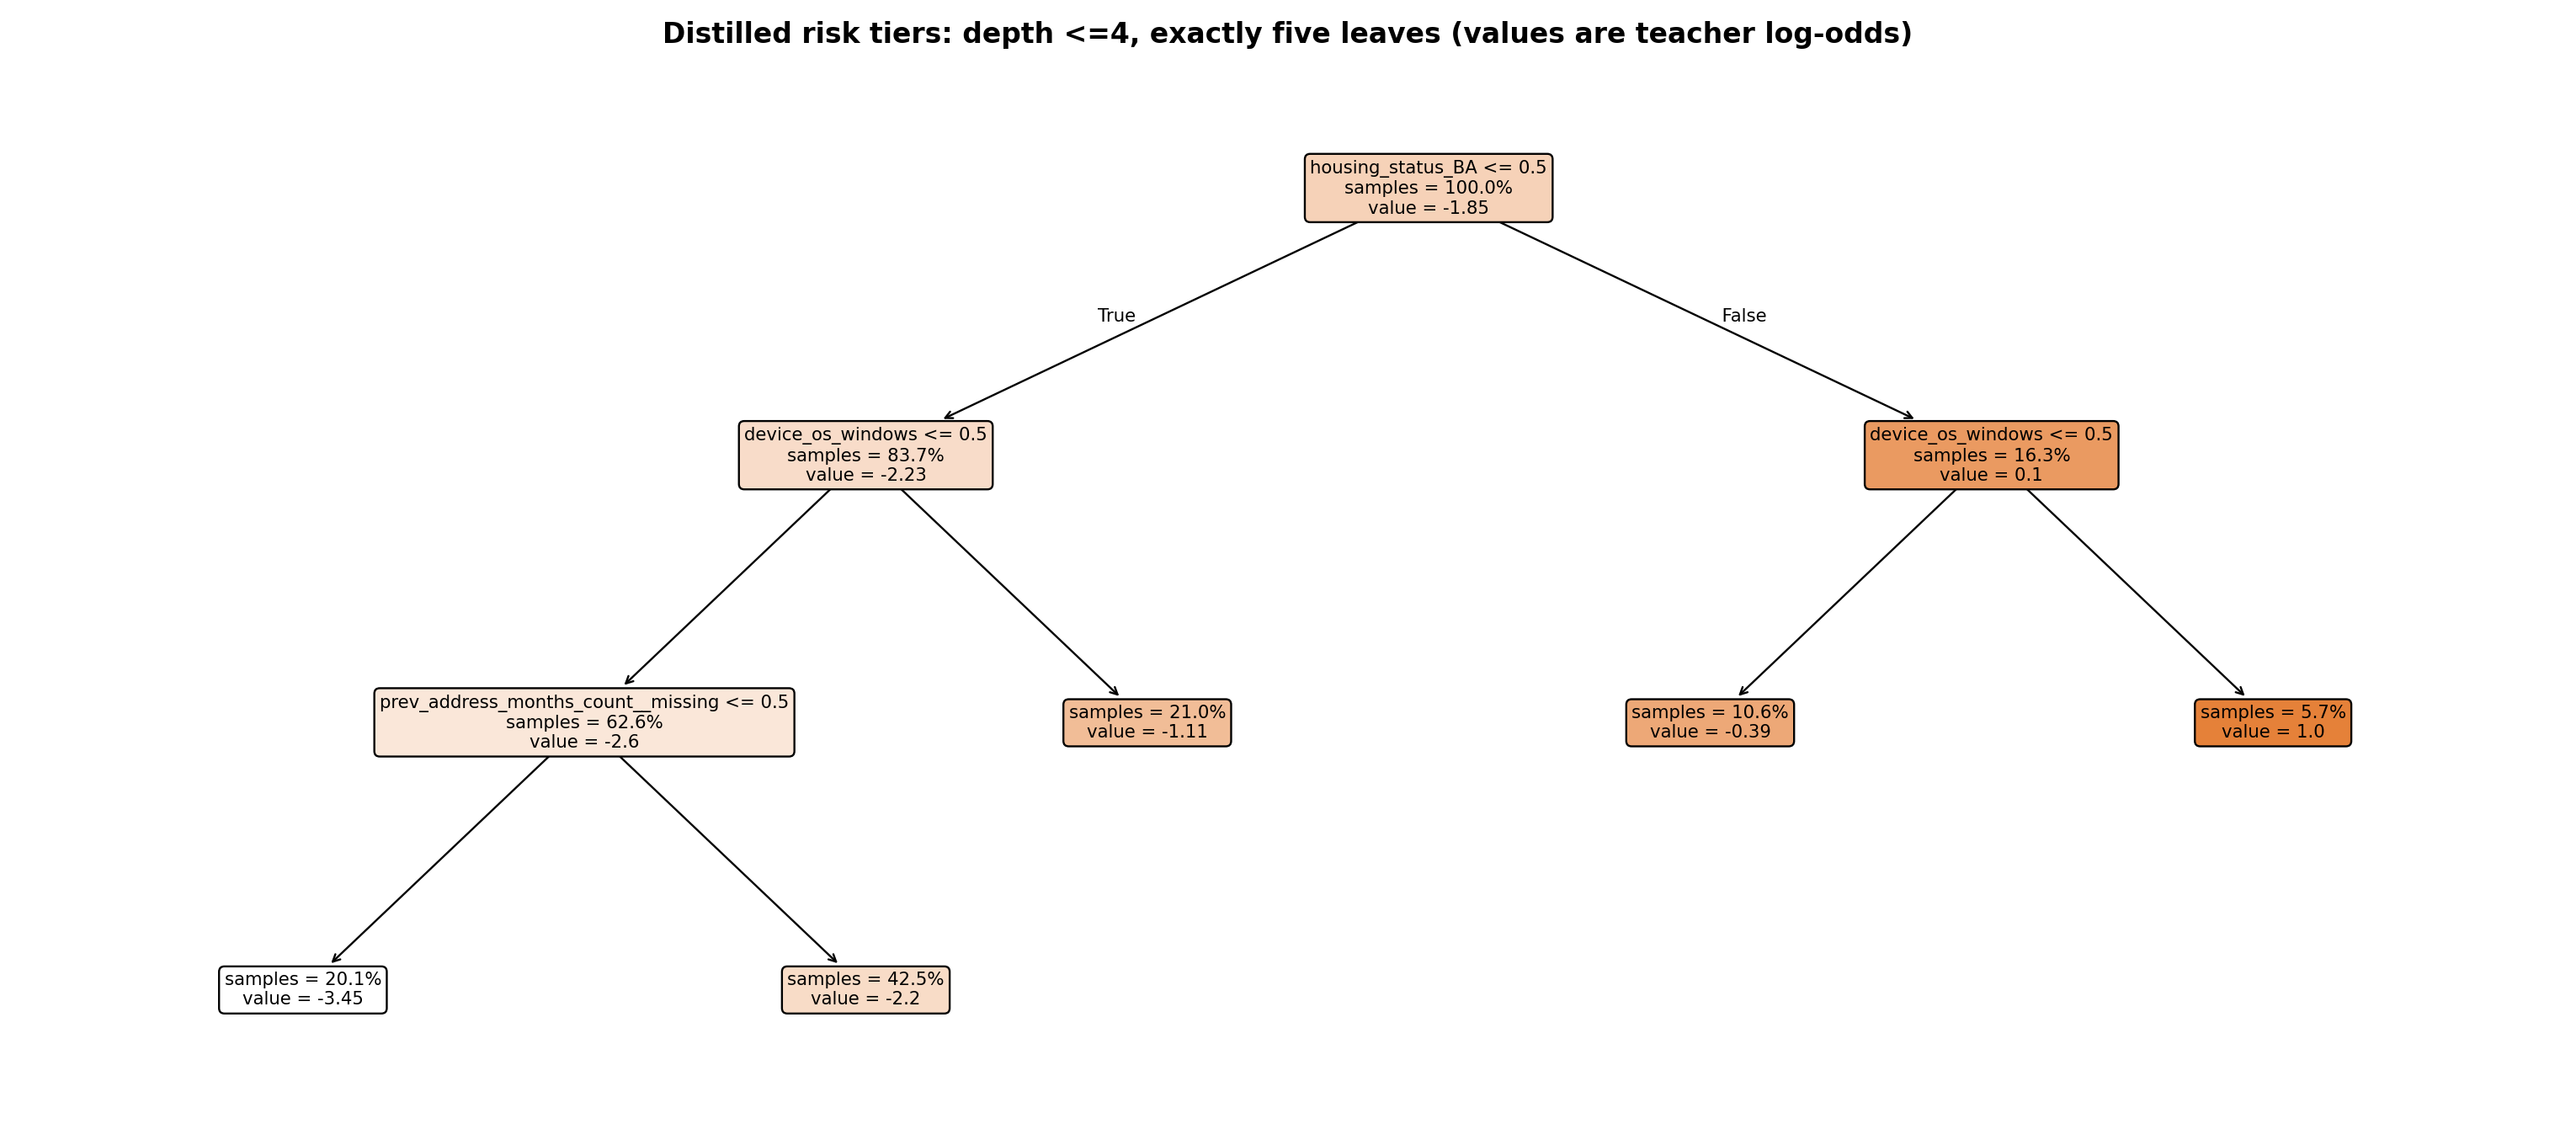

In [6]:
table("shap_importance.csv")
figure("shap_importance.png")
figure("shap_beeswarm.png")
table("distilled_rules.csv")
figure("distilled_tree.png")

### 相同告警量

用验证集 LightGBM 告警比例冻结审核预算，在测试月对所有方法审核完全相同的 K 条。排序只使用测试特征分数；边界并列分数使用 seed=42 的行哈希分配，标签只用于事后统计。浅层树整叶报警粒度较粗，满足整分数 FPR≤5% 的冻结阈值可能一条也不报；不能把该退化结果解释为公平性改善。严格同 K 结果展示其风险排序的实际取舍。

,model,k,n,fraud,tp,fp,fn,tn,recall,fpr,precision,alerts,alert_rate
0,logistic_regression,5463,96843,1428,760,4703,668,90712,0.532213,0.049290,0.139118,5463,0.056411
1,lightgbm,5463,96843,1428,784,4679,644,90736,0.549020,0.049038,0.143511,5463,0.056411
2,mlp,5463,96843,1428,759,4704,669,90711,0.531513,0.049300,0.138935,5463,0.056411
3,isolation_forest,5463,96843,1428,105,5358,1323,90057,0.073529,0.056155,0.019220,5463,0.056411
4,distilled_tree,5463,96843,1428,491,4972,937,90443,0.343838,0.052109,0.089877,5463,0.056411


{
  "budget_rate": 0.05641224761482139,
  "test_k": 5463,
  "teacher_tp": 784,
  "rules_tp": 491,
  "caught_difference": 293,
  "recall_gap": 0.20518207282913165,
  "bootstrap95": [
    0.17857142857142858,
    0.23319327731092437
  ],
  "bootstrap_replicates": 500,
  "bootstrap_conditioning": "paired positive-class bootstrap, fixed predictions and K; no retraining or re-ranking",
  "tie_break": "seed42 row hash, independent of labels and month ordering",
  "rules_cutoff_tie_count": 6090,
  "rules_selected_from_cutoff_tie": 5463
}


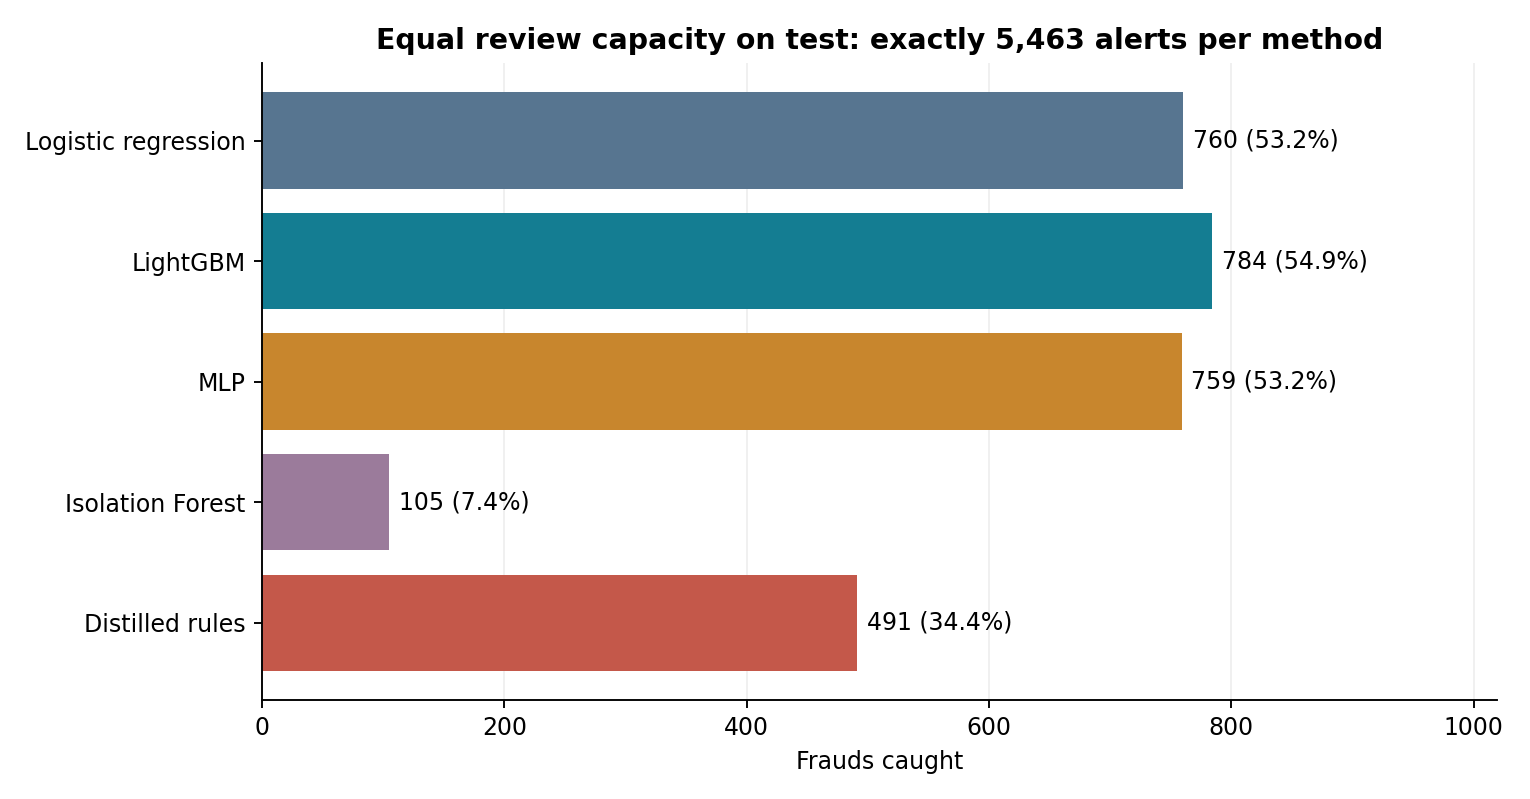

学生树对教师的拟合： {'validation_spearman': 0.6011543770497564, 'validation_r2': 0.3799757935251633, 'validation_logit_mae': 1.2442621629395505, 'validation_frozen_decision_agreement': 0.9435877523851786, 'test_spearman': 0.6375855275265475, 'test_r2': 0.42787374363220076, 'test_logit_mae': 1.1801225524786454, 'test_frozen_decision_agreement': 0.9490309056927192}


In [7]:
table("same_budget.csv")
print(json.dumps(evaluation["rules_comparison"], ensure_ascii=False, indent=2))
figure("equal_budget.png")
print("学生树对教师的拟合：", explanation["student_fidelity"])

## 6. 公平性与时间漂移

使用同一个全局冻结阈值，比较 age<50 与 age≥50 的正常申请误报率及 Wilson 95% 区间。年龄已按十岁取整；组间统计差异不单独证明歧视原因。另导出 >50/≤50 边界敏感性结果。

月 0–5 的召回来自训练内预测，有乐观偏差；月 6 为验证，月 7 为单次最终测试。图能显示实际变化，但不能把八个月都称为独立跨期验证。

,model,split,group,n,fraud,tp,fp,fn,tn,recall,fpr,precision,alerts,alert_rate,fpr_ci_low,fpr_ci_high
0,logistic_regression,validation,age<50,87056,879,361,3005,518,83172,0.410694,0.034870,0.107249,3366,0.038665,3.366586e-02,0.036116
1,logistic_regression,validation,age>=50,21112,571,373,2330,198,18211,0.653240,0.113432,0.137995,2703,0.128031,1.091670e-01,0.117841
2,lightgbm,validation,age<50,87056,879,397,3118,482,83059,0.451650,0.036181,0.112945,3515,0.040376,3.495509e-02,0.037449
3,lightgbm,validation,age>=50,21112,571,370,2217,201,18324,0.647986,0.107930,0.143023,2587,0.122537,1.037602e-01,0.112247
4,mlp,validation,age<50,87056,879,364,3037,515,83140,0.414107,0.035241,0.107027,3401,0.039067,3.403091e-02,0.036493
5,mlp,validation,age>=50,21112,571,368,2298,203,18243,0.644483,0.111874,0.138035,2666,0.126279,1.076356e-01,0.116257
6,isolation_forest,validation,age<50,87056,879,30,3273,849,82904,0.034130,0.037980,0.009083,3303,0.037941,3.672422e-02,0.039277
7,isolation_forest,validation,age>=50,21112,571,74,2062,497,18479,0.129597,0.100385,0.034644,2136,0.101175,9.634942e-02,0.104569
8,distilled_tree,validation,age<50,87056,879,0,0,879,86177,0.000000,0.000000,0.000000,0,0.000000,-3.388132e-21,0.000045
9,distilled_tree,validation,age>=50,21112,571,0,0,571,20541,0.000000,0.000000,0.000000,0,0.000000,0.000000e+00,0.000187


,model,split,fpr_gap_older_minus_younger,fpr_ratio_older_to_younger
0,logistic_regression,validation,0.078562,3.252979
1,lightgbm,validation,0.071749,2.983042
2,mlp,validation,0.076632,3.174498
3,isolation_forest,validation,0.062405,2.643093
4,distilled_tree,validation,0.000000,NaN
5,logistic_regression,test,0.062928,3.407300
6,lightgbm,test,0.066317,2.881706
7,mlp,test,0.075472,2.739174
8,isolation_forest,test,0.079943,2.521058
9,distilled_tree,test,0.000000,NaN


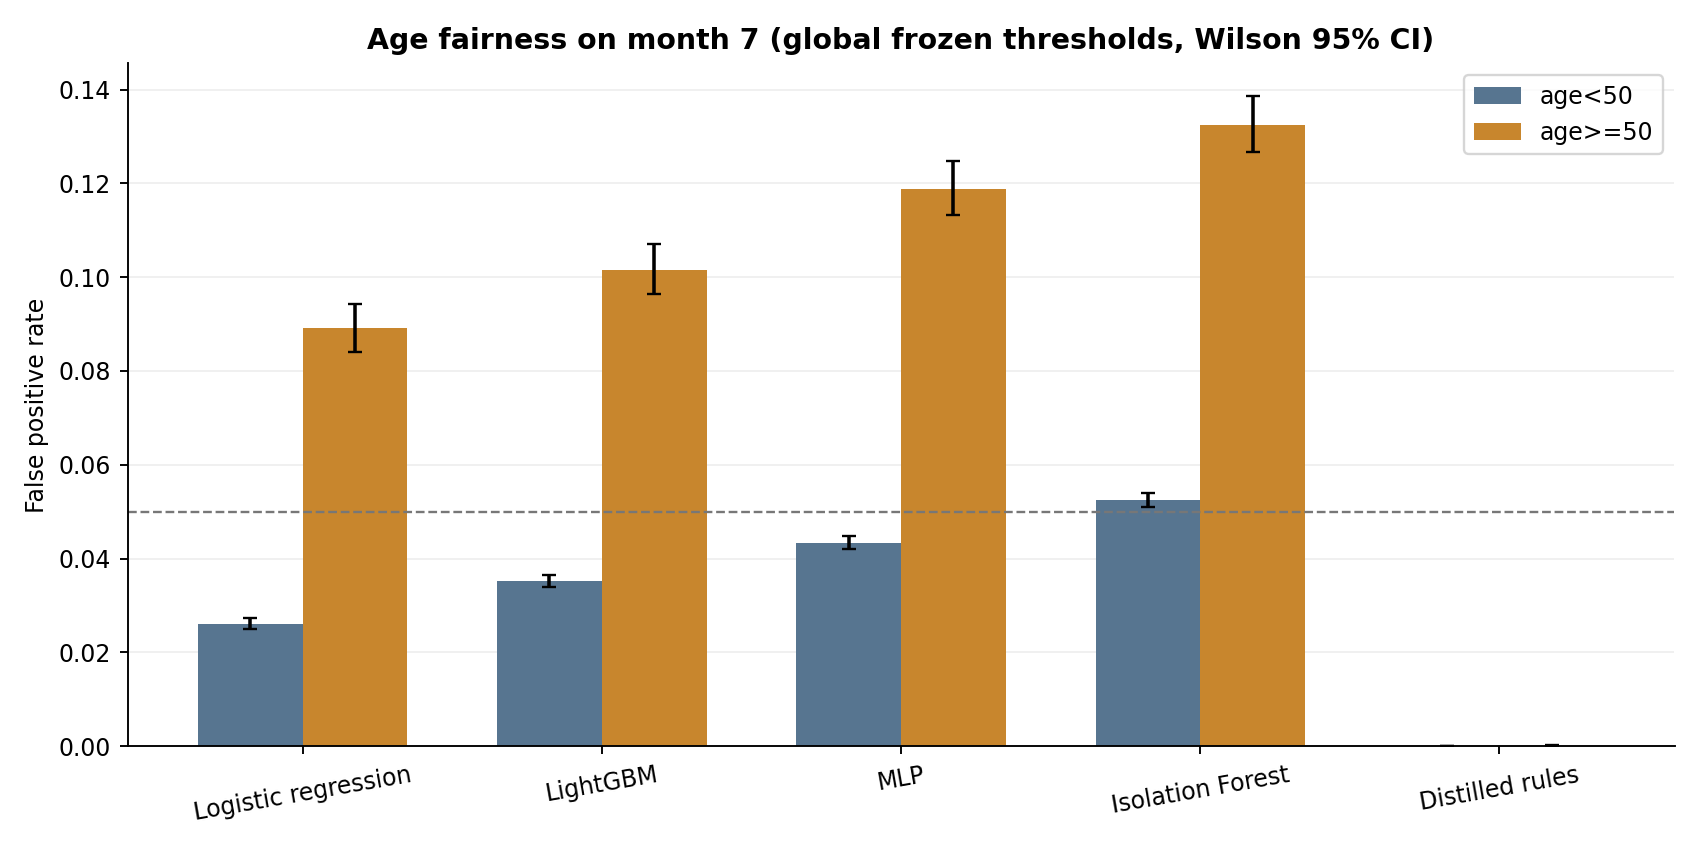

,month,split,n,fraud,tp,fp,fn,tn,recall,fpr,...,alert_rate,threshold,pr_auc_ap,pr_auc_trapezoid,roc_auc,model,recall_ci_low,recall_ci_high,recall_ci,fpr_ci
0,0,train_in_sample,132440,1500,760,5053,740,125887,0.506667,0.038590,...,0.043892,0.814578,0.183010,0.182487,0.923082,lightgbm,0.481381,0.531918,NaN,NaN
1,1,train_in_sample,127620,1198,620,3946,578,122476,0.517529,0.031213,...,0.035778,0.814578,0.163006,0.162558,0.929548,lightgbm,0.489223,0.545724,NaN,NaN
2,2,train_in_sample,136979,1198,588,3946,610,131835,0.490818,0.029062,...,0.033100,0.814578,0.167855,0.167026,0.930842,lightgbm,0.462584,0.519111,NaN,NaN
3,3,train_in_sample,150936,1392,879,7342,513,142202,0.631466,0.049096,...,0.054467,0.814578,0.185204,0.184798,0.939262,lightgbm,0.605794,0.656413,NaN,NaN
4,4,train_in_sample,127691,1452,922,6607,530,119632,0.634986,0.052337,...,0.058963,0.814578,0.201989,0.201474,0.934837,lightgbm,0.609897,0.659363,NaN,NaN
5,5,train_in_sample,119323,1411,757,4486,654,113426,0.536499,0.038045,...,0.043940,0.814578,0.213515,0.213013,0.929847,lightgbm,0.510416,0.562384,NaN,NaN
6,6,validation,108168,1450,767,5335,683,101383,0.528966,0.049992,...,0.056412,0.814578,0.176903,0.176421,0.891090,lightgbm,0.503230,0.554547,NaN,NaN
7,7,test,96843,1428,761,4175,667,91240,0.532913,0.043756,...,0.050969,0.814578,0.210447,0.209799,0.892808,lightgbm,0.506983,0.558667,"[0.5069826206845619, 0.5586671057016409]","[0.04247657862167973, 0.04507260276746874]"


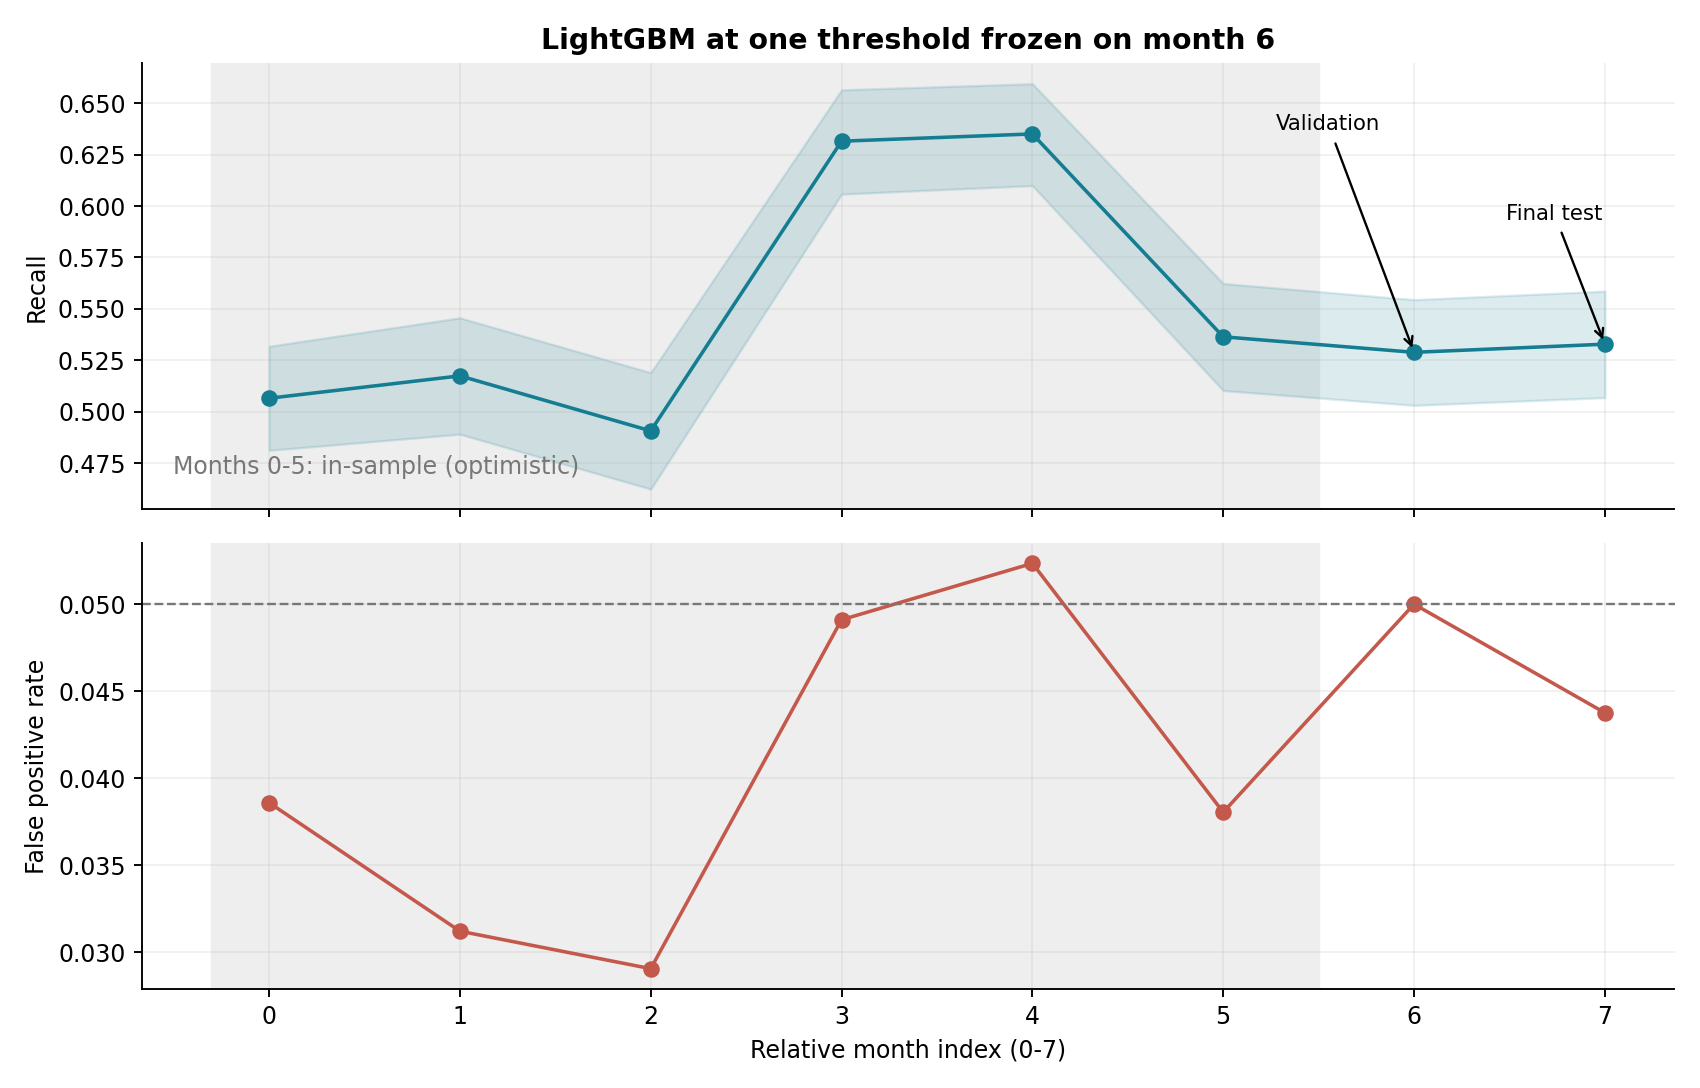

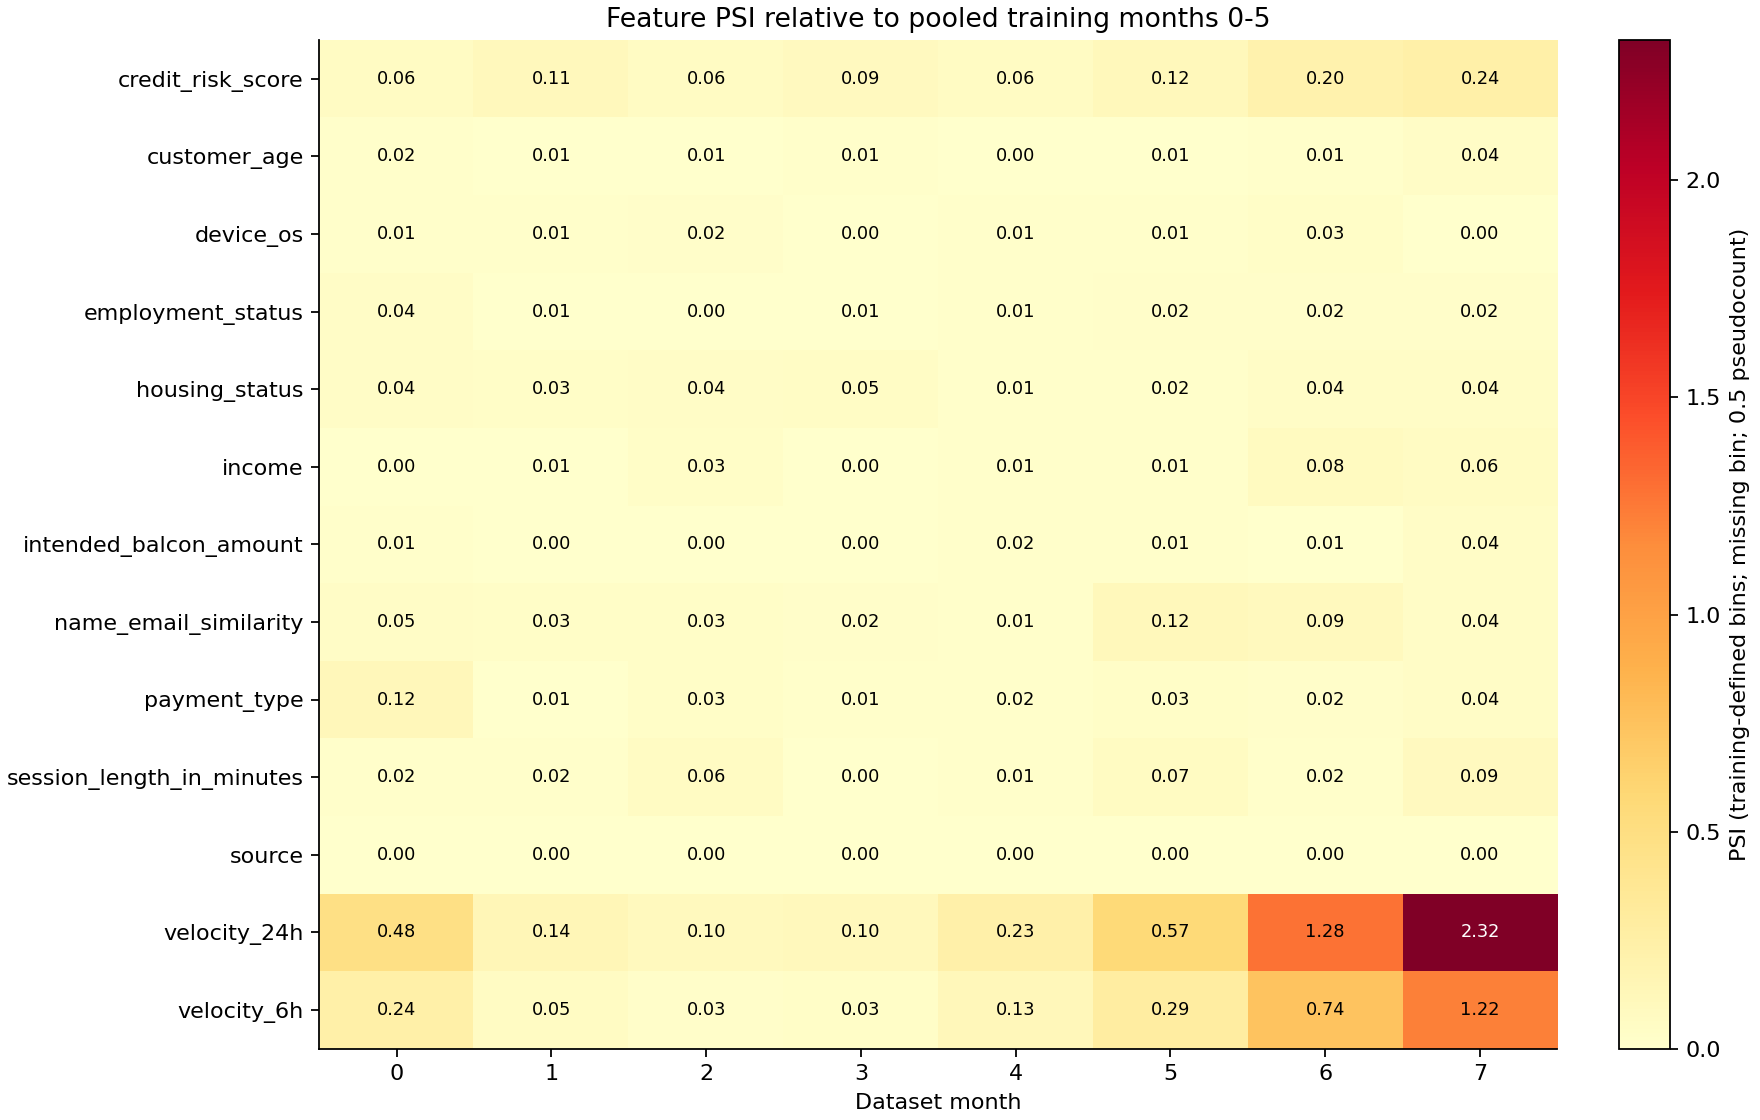

In [8]:
table("fairness.csv")
table("fairness_gaps.csv")
figure("fairness.png")
table("monthly_recall.csv")
figure("monthly_recall.png")
figure("eda_monthly_psi.png")

## 7. 补充分析（事后探索）

这一节在看过第 8 月结果之后追加，沿用相同纪律：新模型只在月 0–5 拟合，早停、阈值和推荐规则数只看月 6，月 7 只报告；冻结文件的哈希在运行前后一致。

- **A. 规则复杂度**：叶子数 5→64，看整叶规则何时摆脱零告警、多少条规则接近教师。
- **B. 年龄差异**：两组基础欺诈率、去掉年龄的对照模型、其余字段能否猜出年龄、分组阈值的代价。
- **C. velocity 漂移**：velocity_* 总体随月份下降，可能携带时间信息；去掉它们后重训对比。

冻结文件未改变： True | 同配置重训复现： {'best_iteration': 263, 'frozen_best_iteration': 263, 'max_abs_val_score_diff': 0.0, 'max_abs_test_score_diff': 0.0, 'reproduced': True}


,leaves,actual_leaves,depth,threshold,alerted_leaves,mean_conditions_alerted,max_conditions_alerted,features_used,val_whole_recall,val_whole_fpr,...,test_whole_precision,val_same_budget_recall,test_same_budget_recall,test_same_budget_tp,val_spearman,test_spearman,val_r2,test_r2,test_ap,fit_seconds
0,5,5,4,0.100166,0,0.0,0,4,0.000000,0.000000,...,0.000000,0.187586,0.180672,258,0.629342,0.656744,0.398218,0.434449,0.039187,8.582348
1,8,8,5,1.001170,0,0.0,0,5,0.000000,0.000000,...,0.000000,0.330345,0.343838,491,0.664996,0.689440,0.451509,0.488907,0.056661,9.274838
2,12,12,6,1.001170,0,0.0,0,6,0.000000,0.000000,...,0.000000,0.330345,0.343838,491,0.708689,0.720635,0.511691,0.537537,0.060225,10.783136
3,16,16,7,1.001170,0,0.0,0,7,0.000000,0.000000,...,0.000000,0.330345,0.343838,491,0.731968,0.748562,0.542122,0.571456,0.061700,12.545289
4,24,24,8,1.001170,0,0.0,0,11,0.000000,0.000000,...,0.000000,0.330345,0.343838,491,0.755324,0.773699,0.584519,0.616013,0.065634,13.102881
5,32,32,9,0.653211,1,3.0,3,14,0.316552,0.041033,...,0.104484,0.359310,0.383053,547,0.780802,0.792128,0.618839,0.641664,0.072638,12.941439
6,48,48,10,0.653211,2,5.0,5,16,0.304828,0.035739,...,0.112884,0.372414,0.374650,535,0.803380,0.815154,0.657685,0.682253,0.088043,14.545137
7,64,64,11,0.940009,2,5.5,6,17,0.338621,0.042898,...,0.126608,0.387586,0.401961,574,0.822337,0.836589,0.681571,0.706990,0.091930,15.557397


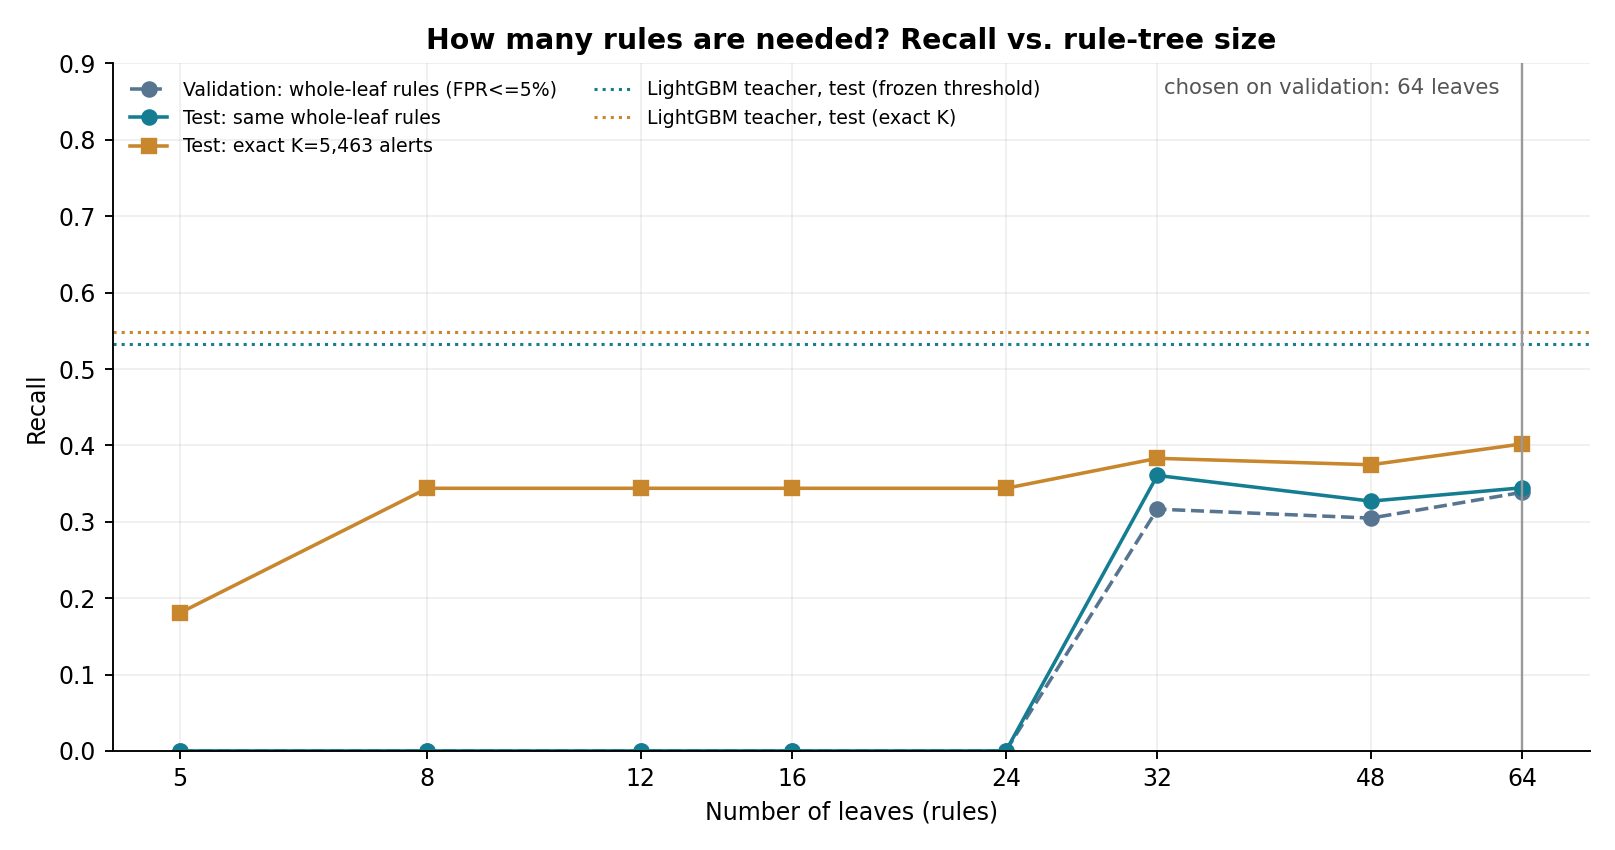

推荐叶子数（验证月选择）： 64


,rule_id,teacher_log_odds,alert,conditions,path,train_rows,validation_rows,validation_fraud_rate,test_rows,test_fraud,test_fraud_rate
0,L64-R1,1.797219,True,5,housing_status 等于 BA 且 device_os 等于 windows 且 ...,16993,2426,0.129431,2180,359,0.164679
1,L64-R2,1.034979,True,6,housing_status 等于 BA 且 device_os 不等于 windows 且...,14557,2643,0.066969,1706,133,0.077960
2,L64-R3,0.940009,False,5,housing_status 等于 BA 且 device_os 等于 windows 且 ...,14037,1830,0.069945,1957,108,0.055187
3,L64-R4,0.537795,False,5,housing_status 不等于 BA 且 device_os 等于 windows 且...,15924,2121,0.040075,1255,68,0.054183
4,L64-R5,0.374701,False,8,housing_status 不等于 BA 且 device_os 不等于 windows ...,6458,1685,0.021958,690,18,0.026087
...,...,...,...,...,...,...,...,...,...,...,...
59,L64-R60,-3.559666,False,9,housing_status 不等于 BA 且 device_os 不等于 windows ...,25269,2260,0.000442,2577,5,0.001940
60,L64-R61,-3.979124,False,8,housing_status 不等于 BA 且 device_os 不等于 windows ...,24260,3557,0.001125,3811,4,0.001050
61,L64-R62,-4.112959,False,8,housing_status 不等于 BA 且 device_os 不等于 windows ...,32023,3687,0.000814,4201,3,0.000714
62,L64-R63,-4.158537,False,8,housing_status 不等于 BA 且 device_os 不等于 windows ...,16350,1979,0.001011,2778,2,0.000720


In [9]:
extensions = json.loads((OUT / "extensions.json").read_text(encoding="utf-8"))
print("冻结文件未改变：", extensions["frozen_artifacts_unchanged"], "| 同配置重训复现：", extensions["reproduction"])
table("ext_rule_complexity.csv")
figure("ext_rule_complexity.png")
print("推荐叶子数（验证月选择）：", extensions["rules"]["chosen_leaves"])
table("ext_rules_recommended.csv")

,setting,split,group,base_fraud_rate,n,fraud,tp,fp,fn,tn,recall,fpr,precision,alerts,alert_rate,fpr_ci_low,fpr_ci_high
0,global_threshold,validation,age<50,0.010097,87056,879,397,3118,482,83059,0.451650,0.036181,0.112945,3515,0.040376,0.034955,0.037449
1,global_threshold,validation,age>=50,0.027046,21112,571,370,2217,201,18324,0.647986,0.107930,0.143023,2587,0.122537,0.103760,0.112247
2,global_threshold,test,age<50,0.011999,84176,1010,472,2931,538,80235,0.467327,0.035243,0.138701,3403,0.040427,0.034011,0.036518
3,global_threshold,test,age>=50,0.032999,12667,418,289,1244,129,11005,0.691388,0.101559,0.188519,1533,0.121023,0.096334,0.107034
4,no_age_model,validation,age<50,0.010097,87056,879,403,3439,476,82738,0.458476,0.039906,0.104893,3842,0.044133,0.038620,0.041234
5,no_age_model,validation,age>=50,0.027046,21112,571,344,1896,227,18645,0.602452,0.092303,0.153571,2240,0.106101,0.088421,0.096338
6,no_age_model,test,age<50,0.011999,84176,1010,465,2667,545,80499,0.460396,0.032068,0.148467,3132,0.037208,0.030892,0.033288
7,no_age_model,test,age>=50,0.032999,12667,418,264,940,154,11309,0.631579,0.076741,0.219269,1204,0.095050,0.072159,0.081589
8,group_thresholds,validation,age<50,0.010097,87056,879,441,4308,438,81869,0.501706,0.049990,0.092862,4749,0.054551,0.048555,0.051465
9,group_thresholds,validation,age>=50,0.027046,21112,571,274,1027,297,19514,0.479860,0.049998,0.210607,1301,0.061624,0.047100,0.053063


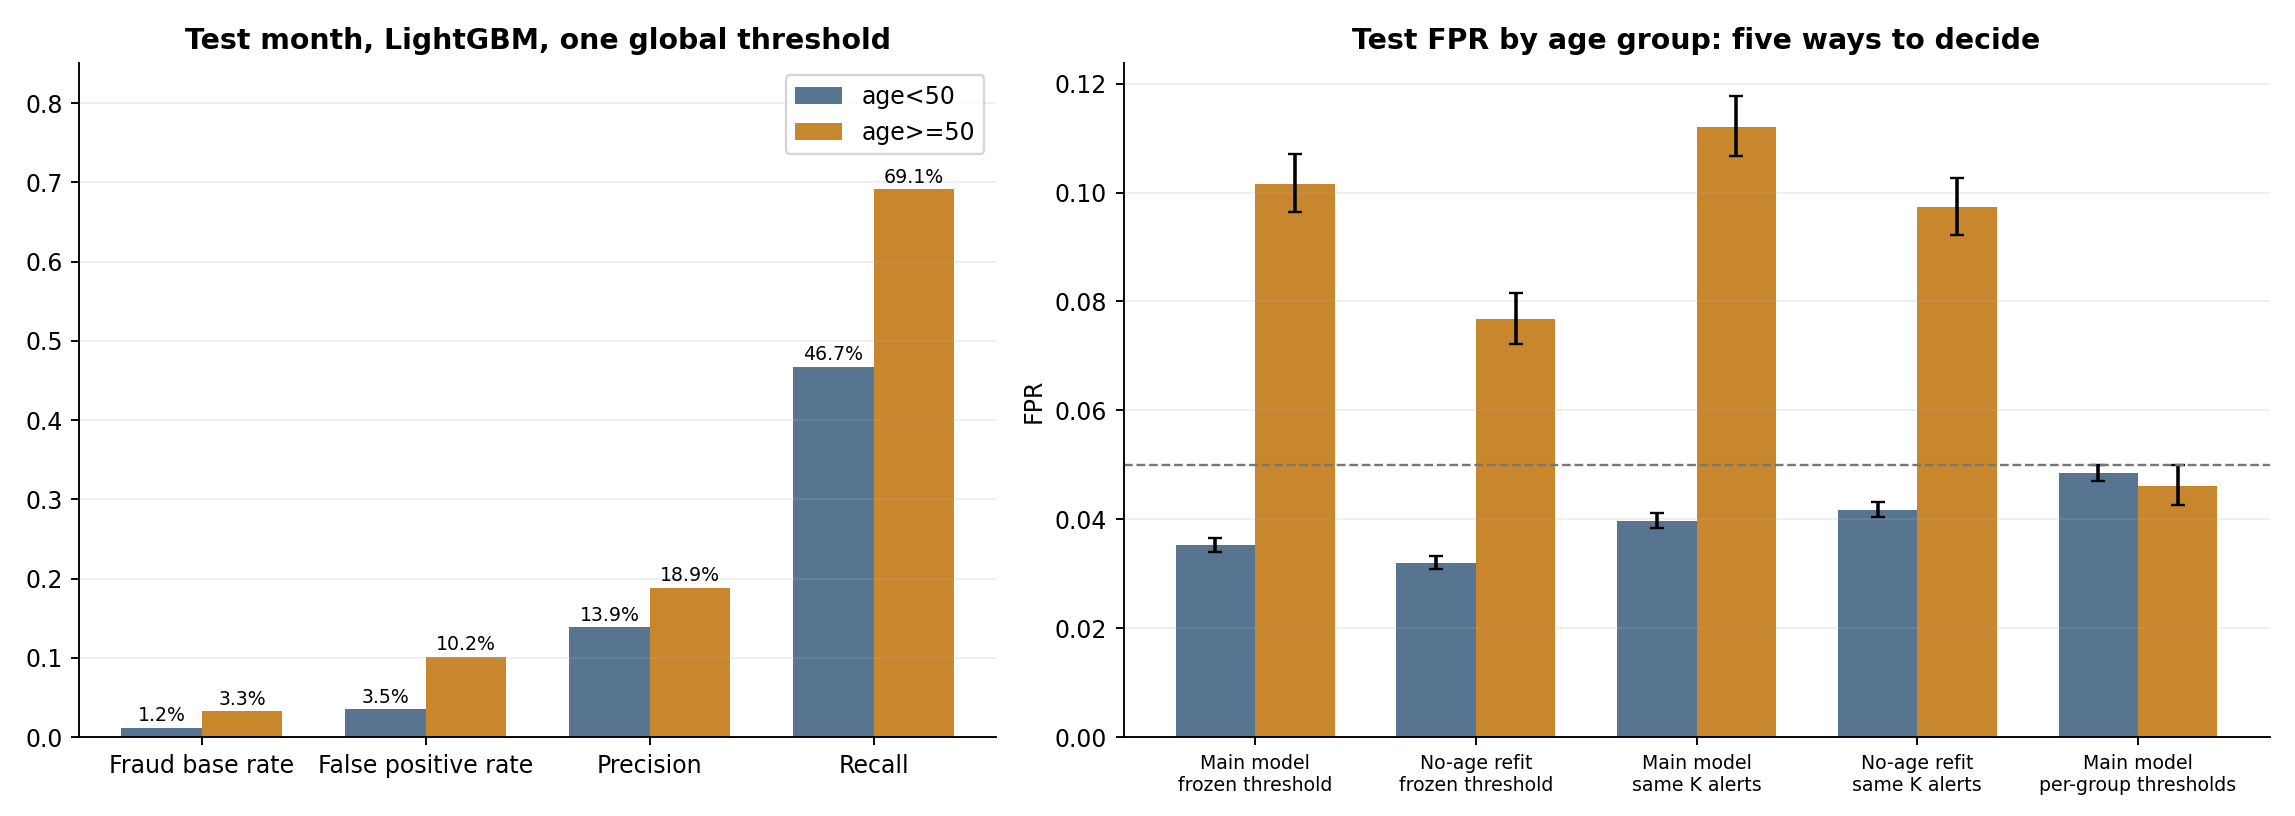

{
  "target": "age>=50",
  "features": "all model inputs except customer_age",
  "train_rows": 300000,
  "roc_auc": {
    "validation": 0.8422148747651178,
    "test": 0.8343196367730317
  },
  "top_gain_features": {
    "date_of_birth_distinct_emails_4w": 593723.2,
    "employment_status": 111192.3,
    "housing_status": 72621.7,
    "current_address_months_count": 31035.3,
    "device_os": 23152.1
  }
}


In [10]:
table("ext_fairness_context.csv")
figure("ext_fairness_context.png")
print(json.dumps(extensions["fairness"]["age_proxy"], ensure_ascii=False, indent=2))

,month,feature,median,mean,p10,p90,psi
0,0,velocity_6h,7623.0460,7436.9805,3241.628174,11479.094922,0.243799
1,0,velocity_24h,5950.3690,5882.4090,4114.656201,7399.654248,0.476092
2,0,velocity_4w,6343.5910,6189.1826,5592.517676,6757.851416,2.553622
3,1,velocity_6h,6482.0674,6821.4100,2719.603198,11484.697852,0.054679
4,1,velocity_24h,5340.6610,5544.7460,3702.221948,7453.474756,0.138512
5,1,velocity_4w,5446.3240,5392.2240,5145.657373,5664.642236,1.559206
6,2,velocity_6h,6164.5073,6465.4106,2495.732910,10784.800586,0.025275
7,2,velocity_24h,5044.8228,5293.5350,3736.354688,7199.270801,0.096368
8,2,velocity_4w,5462.1670,5356.3022,5082.616504,5666.122266,1.306196
9,3,velocity_6h,5940.0986,5960.1570,1976.724243,9479.324219,0.031019


,variant,label,dropped,best_iteration,threshold,val_ap,val_recall,test_ap,test_roc_auc,test_recall,...,test_fpr_shift_from_target,test_same_budget_recall,test_same_budget_tp,max_abs_val_score_diff_vs_frozen,max_abs_test_score_diff_vs_frozen,frozen_best_iteration,same_budget_recall_diff_vs_main,same_budget_diff_ci95,ap_diff_vs_main,ap_diff_ci95
0,reference_refit,同配置重训（含全部特征）,—,263,0.814578,0.176903,0.528966,0.210447,0.892808,0.532913,...,-0.006244,0.549020,784,0.0,0.0,263.0,NaN,NaN,NaN,NaN
1,no_age,去掉 customer_age,customer_age,330,0.819893,0.173901,0.515172,0.204992,0.889692,0.510504,...,-0.012197,0.556723,795,NaN,NaN,NaN,0.007703,"[-0.0070028011204481795, 0.022776610644257688]",-0.005455,"[-0.013492198992281037, 0.0020279939429994056]"
2,no_velocity_short,去掉 velocity_6h / 24h,"velocity_6h,velocity_24h",209,0.823786,0.175465,0.514483,0.210547,0.890994,0.529412,...,-0.006003,0.549720,785,NaN,NaN,NaN,0.000700,"[-0.012972689075630251, 0.014705882352941176]",0.000100,"[-0.005820569524766901, 0.006558348127048518]"
3,no_velocity_all,去掉全部 velocity_*,"velocity_6h,velocity_24h,velocity_4w",338,0.807887,0.177935,0.520690,0.216463,0.893591,0.510504,...,-0.012102,0.559524,799,NaN,NaN,NaN,0.010504,"[-0.0035014005602240898, 0.023476890756302504]",0.006016,"[-0.00039641279645803983, 0.01269492478847831]"


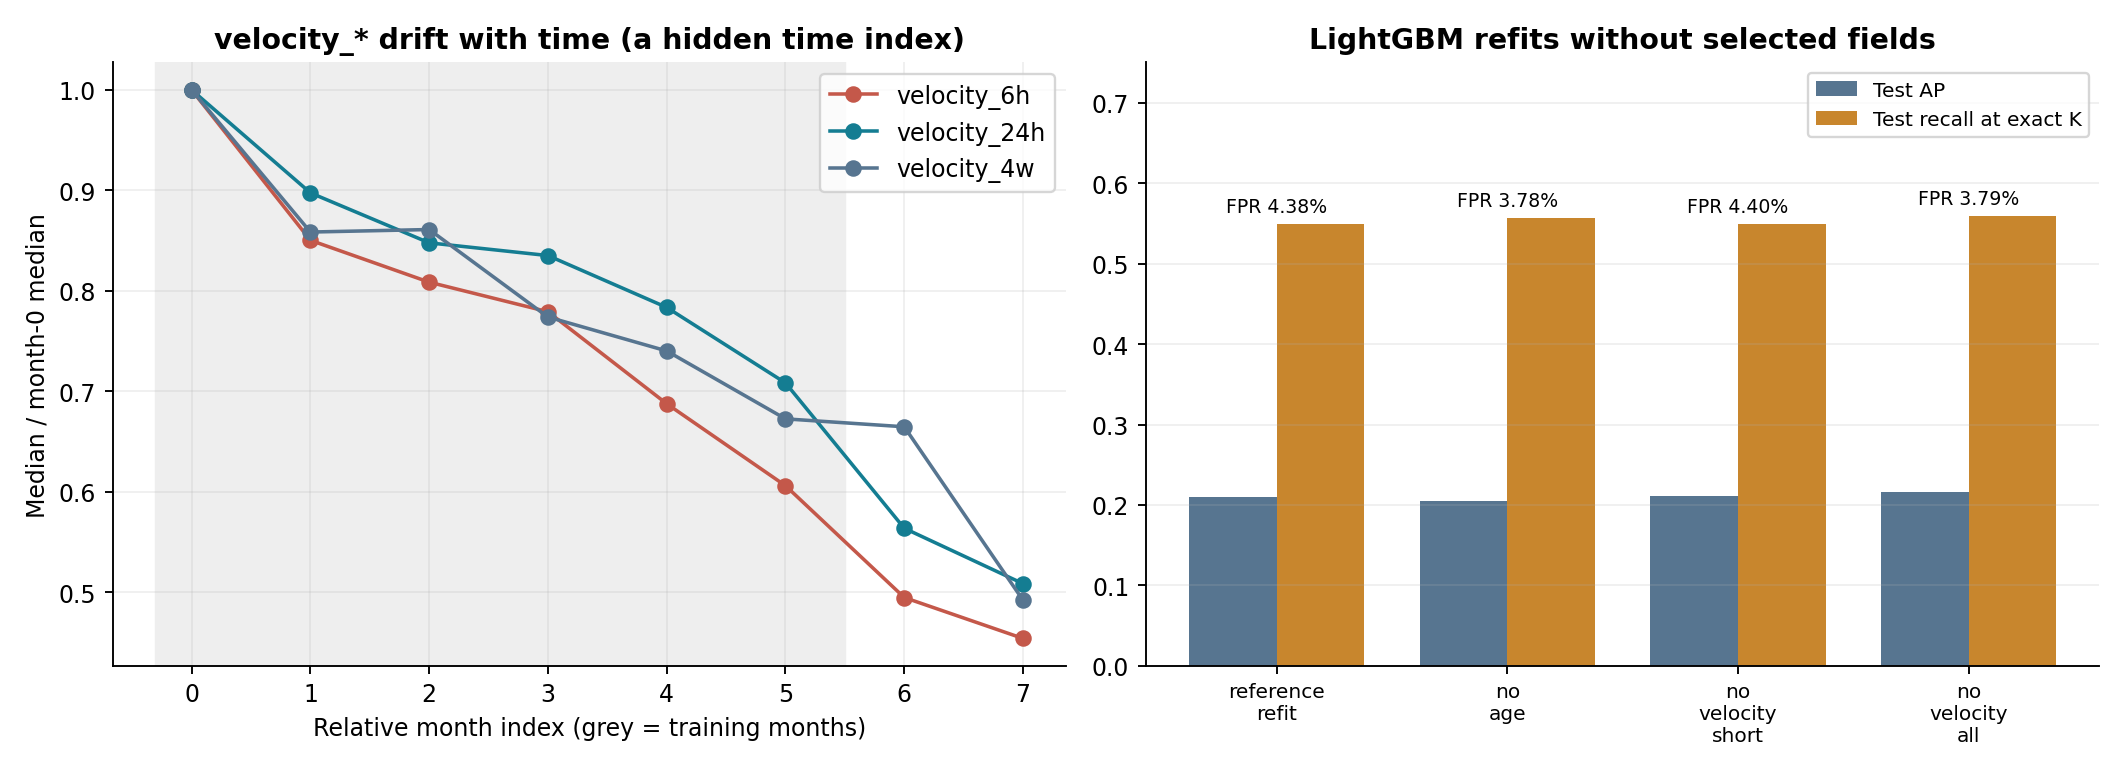

In [11]:
table("ext_velocity_monthly.csv")
table("ext_feature_ablation.csv")
figure("ext_drift_ablation.png")

## 8. 滚动时间回测（事后稳健性检验）

测试第5–8月：例如第1–3月训练、第4月验证、第5月测试，然后依次前移。每个窗口只用自己的过去数据重新拟合类别映射、选择三组LightGBM配置、早停和阈值。三个消融模型沿用本窗基线配置，各自早停。

这里统一审核每月5%的申请，K=floor(0.05*N)，区别于主实验从验证月得到的约5.64%。测试FPR可以偏离验证时的5%约束。全部月份此前已被查看，因此是事后稳健性检验，不是四份新的独立测试；四窗训练集重叠，跨月最小—最大范围也不是置信区间。

冻结主实验未改变： True


,window_id,train_months,validation_month,test_month,train_n,validation_n,test_n,test_fraud,selected_num_leaves,selected_reg_lambda,selected_best_iteration,k,validation_k
0,window_5,"[0, 1, 2]",3,4,397039,150936,127691,1452,31,10.0,235,6384,7546
1,window_6,"[0, 1, 2, 3]",4,5,547975,127691,119323,1411,31,10.0,352,5966,6384
2,window_7,"[0, 1, 2, 3, 4]",5,6,675666,119323,108168,1450,15,5.0,545,5408,5966
3,window_8,"[0, 1, 2, 3, 4, 5]",6,7,794989,108168,96843,1428,31,10.0,263,4842,5408


,window_id,test_month,variant,split,policy,threshold,pr_auc_ap,roc_auc,n,fraud,...,recall,fpr,precision,alerts,alert_rate,pr_auc_trapezoid,recall_ci_low,recall_ci_high,fpr_ci_low,fpr_ci_high
2,window_5,4,baseline,test,frozen_threshold,0.833726,0.172423,0.906115,127691,1452,...,0.567493,0.051886,0.111744,7374,0.057749,0.171887,0.541866,0.592764,0.050676,0.053123
3,window_5,4,baseline,test,fixed_review_5pct,0.833726,0.172423,0.906115,127691,1452,...,0.533058,0.044440,0.121241,6384,0.049996,NaN,0.507343,0.558598,0.043317,0.045590
6,window_5,4,no_age,test,frozen_threshold,0.830785,0.173892,0.903258,127691,1452,...,0.557163,0.050761,0.112096,7217,0.056519,0.173454,0.531496,0.582528,0.049564,0.051985
7,window_5,4,no_age,test,fixed_review_5pct,0.830785,0.173892,0.903258,127691,1452,...,0.524105,0.044542,0.119204,6384,0.049996,NaN,0.498387,0.549695,0.043418,0.045694
10,window_5,4,no_velocity_short,test,frozen_threshold,0.836510,0.173063,0.904727,127691,1452,...,0.570248,0.052060,0.111892,7400,0.057952,0.172538,0.544633,0.595492,0.050848,0.053299
11,window_5,4,no_velocity_short,test,fixed_review_5pct,0.836510,0.173063,0.904727,127691,1452,...,0.537879,0.044384,0.122337,6384,0.049996,NaN,0.512169,0.563389,0.043262,0.045534
14,window_5,4,no_velocity_all,test,frozen_threshold,0.836791,0.178373,0.903699,127691,1452,...,0.570248,0.051157,0.113643,7286,0.057060,0.177874,0.544633,0.595492,0.049955,0.052386
15,window_5,4,no_velocity_all,test,fixed_review_5pct,0.836791,0.178373,0.903699,127691,1452,...,0.540634,0.044352,0.122964,6384,0.049996,NaN,0.514927,0.566126,0.043230,0.045502
18,window_6,5,baseline,test,frozen_threshold,0.801896,0.190900,0.892630,119323,1411,...,0.452870,0.032312,0.143628,4449,0.037285,0.190473,0.427061,0.478936,0.031318,0.033337
19,window_6,5,baseline,test,fixed_review_5pct,0.801896,0.190900,0.892630,119323,1411,...,0.516655,0.044414,0.122192,5966,0.049999,NaN,0.490571,0.542649,0.043253,0.045605


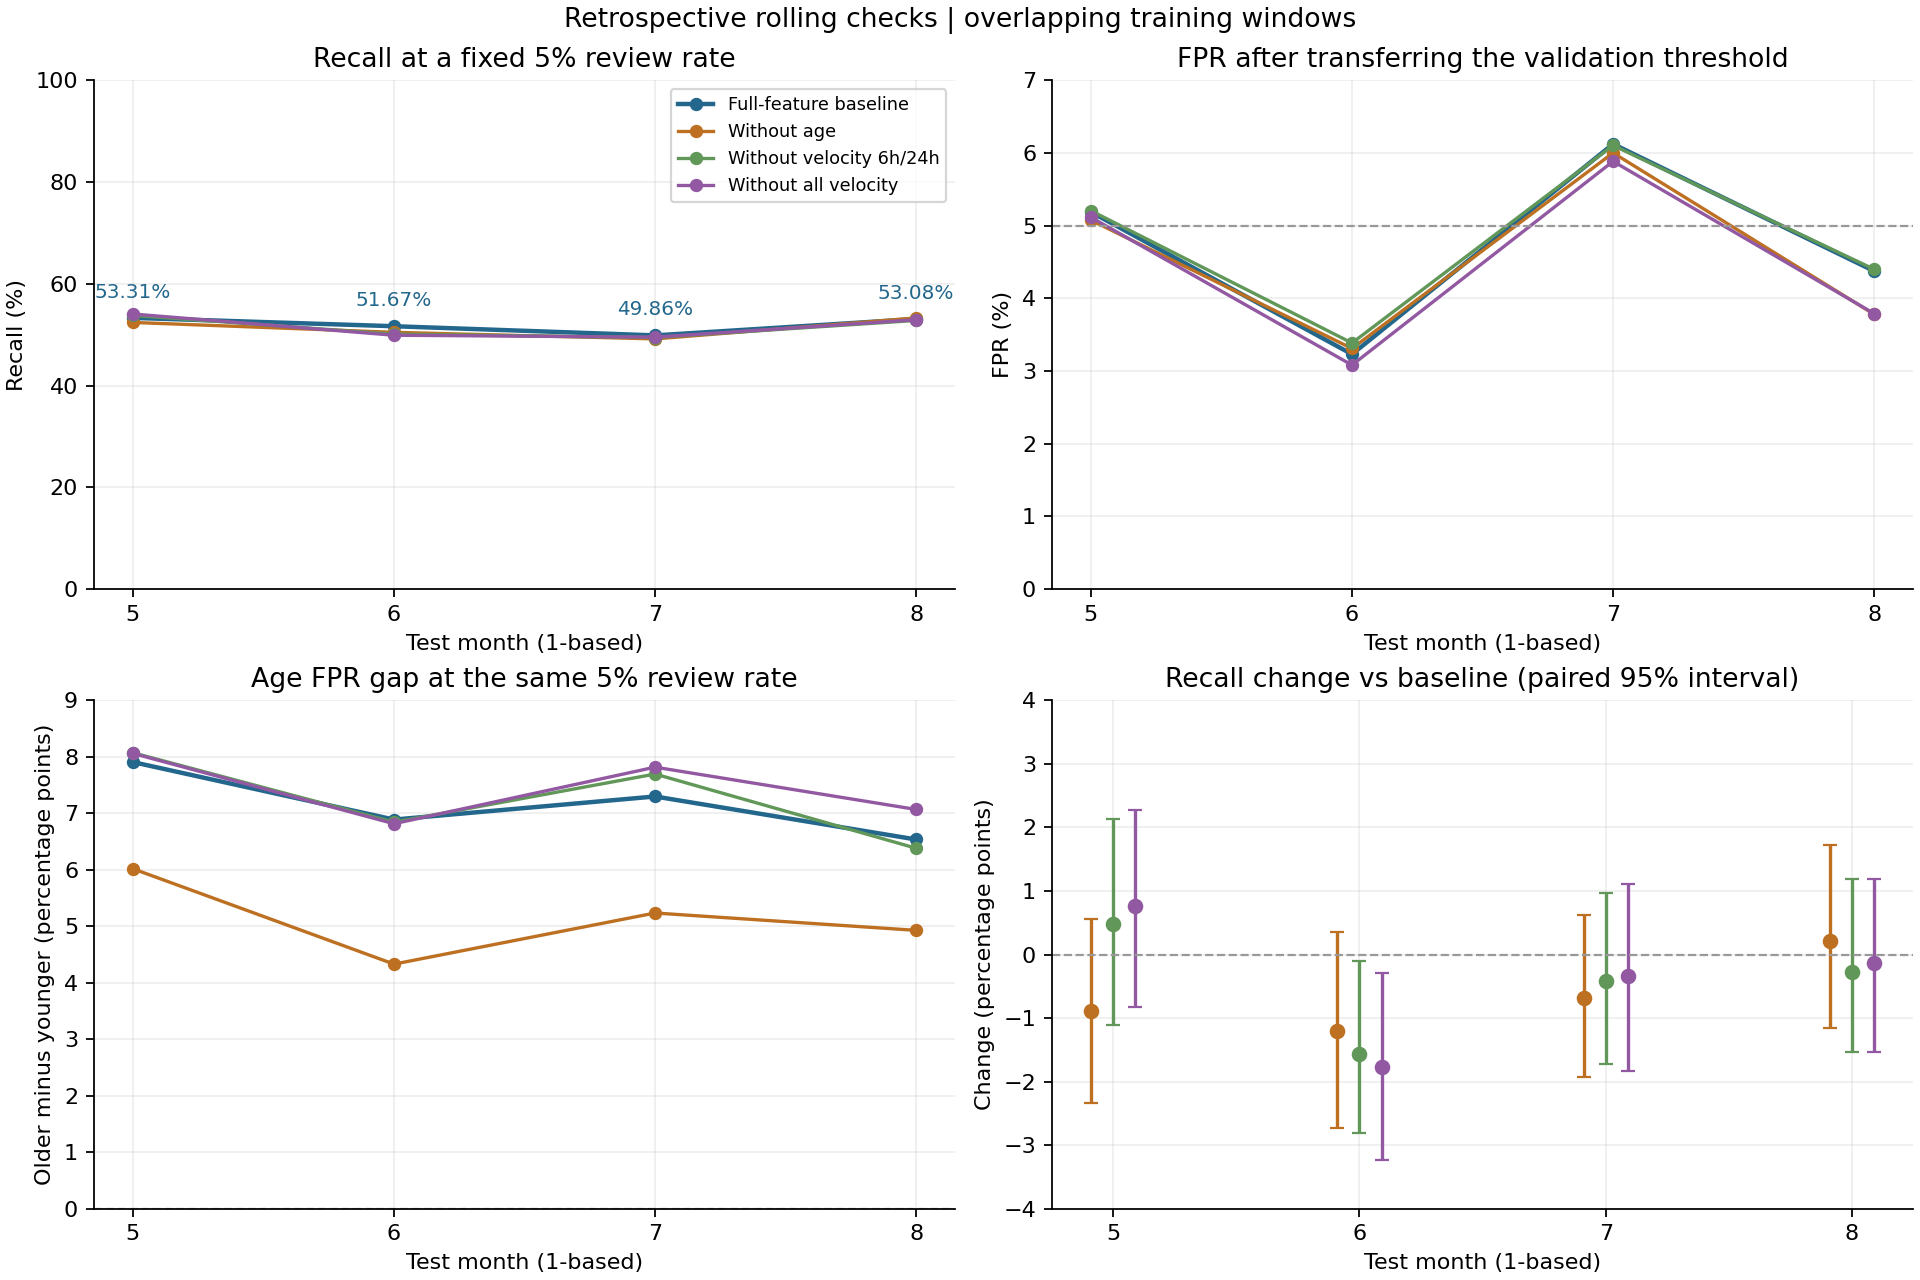

In [12]:
rolling = json.loads((OUT / "rolling_backtest.json").read_text(encoding="utf-8"))
print("冻结主实验未改变：", rolling["frozen_artifacts_unchanged"])
table("rolling_windows.csv")
display(pd.read_csv(OUT / "tables" / "rolling_metrics.csv").query("split == 'test'"))
figure("rolling_backtest.png")

In [13]:
table("rolling_differences.csv")
table("rolling_fairness.csv")
print(json.dumps(rolling["summary"], ensure_ascii=False, indent=2))
print("区间：固定模型、阈值及告警标记的年龄组×标签分层配对bootstrap，500次；不覆盖重训、阈值估计和未来月份的不确定性。")

,window_id,test_month,variant,ap_diff,recall_frozen_diff,recall_topk_diff,fpr_gap_topk_diff,ap_ci_low,ap_ci_high,recall_frozen_ci_low,recall_frozen_ci_high,recall_topk_ci_low,recall_topk_ci_high,fpr_gap_topk_ci_low,fpr_gap_topk_ci_high
0,window_5,4,no_age,0.001469,-0.010331,-0.008953,-0.018872,-0.004925,0.007944,-0.026171,0.005510,-0.023416,0.005510,-0.021259,-0.016403
1,window_5,4,no_velocity_short,0.000640,0.002755,0.004821,0.001652,-0.005430,0.006666,-0.012397,0.017579,-0.011019,0.021350,-0.000870,0.004353
2,window_5,4,no_velocity_all,0.005951,0.002755,0.007576,0.001532,-0.000603,0.011621,-0.014463,0.017906,-0.008264,0.022727,-0.000900,0.004014
3,window_6,5,no_age,-0.006891,-0.005670,-0.012048,-0.025568,-0.013421,0.000288,-0.020553,0.009922,-0.027303,0.003544,-0.028226,-0.023146
4,window_6,5,no_velocity_short,-0.007113,-0.000709,-0.015592,-0.000464,-0.012164,-0.001023,-0.015592,0.012420,-0.028012,-0.001045,-0.003153,0.002131
5,window_6,5,no_velocity_all,-0.006942,-0.012757,-0.017718,-0.000733,-0.012910,-0.000857,-0.026223,0.000000,-0.032264,-0.002835,-0.003548,0.001993
6,window_7,6,no_age,-0.006150,-0.006897,-0.006897,-0.020614,-0.012036,-0.000054,-0.020724,0.008966,-0.019310,0.006207,-0.023410,-0.017704
7,window_7,6,no_velocity_short,-0.001462,-0.001379,-0.004138,0.003970,-0.007008,0.004490,-0.015534,0.013793,-0.017241,0.009655,0.001299,0.006854
8,window_7,6,no_velocity_all,-0.001170,-0.013793,-0.003448,0.005187,-0.007097,0.005740,-0.026897,0.002431,-0.018293,0.011034,0.002557,0.008305
9,window_8,7,no_age,-0.005455,-0.022409,0.002101,-0.016074,-0.013327,0.001741,-0.037482,-0.007003,-0.011572,0.017209,-0.019167,-0.012600


,window_id,test_month,variant,policy,fpr_younger,fpr_older,fpr_gap,fpr_ratio,young_n,older_n,young_fp,older_fp,young_normal,older_normal,young_recall,older_recall,older_fpr_ci_low,older_fpr_ci_high,young_fpr_ci_low,young_fpr_ci_high
0,window_5,4,baseline,frozen_threshold,0.035667,0.123912,0.088245,3.474148,103872,23819,3675,2875,103037,23202,0.493413,0.667747,0.119734,0.128214,0.034552,0.036817
1,window_5,4,baseline,fixed_review_5pct,0.029912,0.108956,0.079045,3.642606,103872,23819,3082,2528,103037,23202,0.465868,0.623987,0.105011,0.113030,0.028889,0.030969
2,window_5,4,no_age,frozen_threshold,0.038578,0.104862,0.066283,2.718146,103872,23819,3975,2433,103037,23202,0.504192,0.628849,0.100985,0.108869,0.037420,0.039772
3,window_5,4,no_age,fixed_review_5pct,0.033483,0.093656,0.060173,2.797103,103872,23819,3450,2173,103037,23202,0.471856,0.594814,0.089974,0.097472,0.032402,0.034599
4,window_5,4,no_velocity_short,frozen_threshold,0.035735,0.124558,0.088823,3.485634,103872,23819,3682,2890,103037,23202,0.491018,0.677472,0.120371,0.128869,0.034619,0.036886
5,window_5,4,no_velocity_short,fixed_review_5pct,0.029552,0.110249,0.080697,3.730620,103872,23819,3045,2558,103037,23202,0.457485,0.646677,0.106283,0.114344,0.028536,0.030604
6,window_5,4,no_velocity_all,frozen_threshold,0.034803,0.123782,0.088979,3.556657,103872,23819,3586,2872,103037,23202,0.494611,0.672609,0.119607,0.128082,0.033701,0.035940
7,window_5,4,no_velocity_all,fixed_review_5pct,0.029543,0.110120,0.080577,3.727469,103872,23819,3044,2555,103037,23202,0.464671,0.643436,0.106156,0.114212,0.028526,0.030594
8,window_6,5,baseline,frozen_threshold,0.022968,0.077364,0.054395,3.368301,98598,20725,2243,1567,97657,20255,0.356004,0.646809,0.073764,0.081124,0.022047,0.023927
9,window_6,5,baseline,fixed_review_5pct,0.032583,0.101456,0.068873,3.113743,98598,20725,3182,2055,97657,20255,0.429330,0.691489,0.097374,0.105690,0.031488,0.033715


{
  "observed_ranges_not_confidence_intervals": true,
  "baseline": {
    "frozen_threshold": {
      "pr_auc_ap": [
        0.17242264948402508,
        0.21044683362965014
      ],
      "recall": [
        0.4528703047484054,
        0.5674931129476584
      ],
      "fpr": [
        0.032312232851618154,
        0.06123615510035795
      ],
      "alert_rate": [
        0.03728535152485271,
        0.06795910065823534
      ]
    },
    "fixed_review_5pct": {
      "pr_auc_ap": [
        0.17242264948402508,
        0.21044683362965014
      ],
      "recall": [
        0.4986206896551724,
        0.5330578512396694
      ],
      "fpr": [
        0.04280249436671383,
        0.04443951552214451
      ],
      "alert_rate": [
        0.04999569272697371,
        0.04999874290790543
      ]
    }
  },
  "ablations": {
    "no_age": {
      "positive_ap_months": 1,
      "positive_topk_recall_months": 1,
      "topk_recall_ci_excludes_zero_months": 0,
      "smaller_age_fpr_gap_month

## 核对与资料

实验仅使用 Base，不使用五个偏差变体。有限候选和单次划分无法给出跨数据集普遍优劣结论；类别加权分数未经概率校准，不能当作真实欺诈概率。阈值需随业务审核量和漂移重新验证。

[Feedzai 官方项目](https://github.com/feedzai/bank-account-fraud) · [官方 Kaggle 数据](https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022) · [官方 datasheet](https://raw.githubusercontent.com/feedzai/bank-account-fraud/main/documents/datasheet.pdf) · [NeurIPS 2022 论文](https://arxiv.org/abs/2211.13358)

In [14]:
verification = json.loads((OUT / "verification.json").read_text(encoding="utf-8"))
print("独立一致性核对：", verification["passed"], "检查数量：", verification["count"])

独立一致性核对： True 检查数量： 604
